# **Data Challenge - Кейс DASHBORG - Конкурс от компании Garage Eight**

## **ЗАДАНИЕ**

Добро пожаловать в Дашборг - город, где данные текут быстрее рек, а доставка пиццы - священный ритуал.

Но в один вечер всё пошло не так: заказы исчезли, маршруты курьеров искажены, горожане в панике. Сбой? Саботаж?


Восстановить порядок под силу лишь лучшим аналитикам… и ты среди них.


<br>

**Описание кейса:**

В Дашборге данные решают всё: от расписания автобусов до прогноза спроса на маргариту с двойной порцией сыра. Каждый заказ пиццы — это не просто ужин, а часть идеально выстроенной системы, где алгоритмы предсказывают вкусы клиентов
быстрее, чем они открывают приложение доставки.


Но этим вечером что-то пошло не так.


Система дала сбой: заказы исчезли, курьеры получили пустые маршруты, а владельцы пиццерий начали получать жалобы от разгневанных клиентов.


Технические специалисты быстро заметили, что сбой не был случайностью. Кто-то намеренно вмешался в систему. Как найти преступника и исправить ситуацию?


В распоряжении следствия оказалась часть восстановленных данных: заказы, адреса и информация о клиентах. Этого недостаточно, чтобы увидеть всю картину, но
достаточно, чтобы начать раскручивать клубок цифрового преступления.


Вся надежда на тебя. Только внимательный анализ сможет пролить свет на этот кулинарно-криминальный хаос и помочь вернуть справедливость голодным жителям Дашборга.

<br>

**Бизнес-цель:**

Восстановить систему доставки, используя
аналитические методы.

<br>

**Описание датасетов:**

Первый датасет:

order_id - ID заказа

order - Состав заказа

order_price - Цена

user_id - ID пользователя

<br>

Второй датасет:

ip - Адрес пользователя

device - Устройство, с которого заказывали

operator_ip - Адрес оператора

user_id - ID пользователя



---



# **РЕШЕНИЕ**



---



> **О версии в репозитории.** Сохранены конкурсное исследование и его исходные результаты. Для локального запуска удалены команды установки пакетов и подключение Google Drive; CSV повторного запуска записываются в `results/rerun/`. Зависимости устанавливаются из `requirements.txt`. Входные данные загружаются из Google Sheets организаторов.



In [ ]:
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import font_manager as fm

import seaborn as sns

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import missingno as msno

import networkx as nx

import mplcyberpunk

from IPython.display import Math

In [ ]:
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.ensemble import IsolationForest

In [ ]:
from pathlib import Path

# Works when Jupyter is started from the repository root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'results').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'results').is_dir():
    raise FileNotFoundError('Start Jupyter from the repository root or notebooks/.')
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'rerun'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)




---



Загрузка данных

In [ ]:
url = 'https://docs.google.com/spreadsheets/d/\
1qhxUaTt_ICIDd24t5DlzJbS22iQ4R4_rwLfvJs2ugFM/export?gid=page_num&format=csv'

# URL-адреса для экспорта данных с каждой страницы в формате CSV
url_1 = url.replace('page_num', '0')
url_2 = url.replace('page_num', '462516170')

# Загружаем данные с первой страницы
df_orders = pd.read_csv(url_1)

# Загружаем данные со второй страницы
df_devices = pd.read_csv(url_2)

Первичное ознакомление с данными

In [ ]:
df_orders.head()

,order_id,order,order_price,user_id
0,999,"Мясной микс, 3 пиццы",1878,102475
1,680,Мясной микс,579,218841
2,687,Мясной микс,579,521065
3,685,Дьябло,560,106146
4,683,Сицилийская,545,854950


In [ ]:
df_orders.sample(5)

,order_id,order,order_price,user_id
271,720,Дьябло,560,229825
691,780,"Дьябло, Сицилийская",1105,639181
961,409,"Мясной микс, 3 пиццы",1878,363821
400,668,Гавайская,520,461209
772,283,NaN,520,365113


In [ ]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   order_id     1000 non-null   int64 
 1   order        731 non-null    object
 2   order_price  1000 non-null   int64 
 3   user_id      1000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 31.4+ KB


DataFrame содержит 1000 записей и 4 столбца:


order_id: Уникальный идентификатор заказа. Все 1000 записей содержат значения.

order: Состав заказа. Здесь есть 731 заполненная запись, что указывает на наличие пропусков.

order_price: Цена заказа. Все 1000 записей содержат значения.

user_id: Уникальный идентификатор пользователя. Все 1000 записей содержат значения.

<br>

Первые выводы

- Пропущенные значения:

В столбце order отсутствуют данные для 269 записей.

- Типы данных:

Все числовые данные (order_id, order_price, user_id) имеют тип int64, что подходит для анализа.
Столбец order имеет тип object, что соответствует текстовым данным.

- Уникальность заказов:

Столбец order_id должен содержать уникальные значения для каждого заказа. Важно проверить, нет ли дубликатов, которые могут указывать на ошибки в данных.

- Анализ цен:

Столбец order_price содержит цены заказов. Можно провести анализ распределения цен, чтобы выявить аномалии или необычные заказы.

- Анализ пользователей:

Столбец user_id позволяет анализировать поведение пользователей. Можно выявить, какие пользователи сделали больше всего заказов или какие заказы были самыми дорогими.



---



In [ ]:
df_devices.head()

,ip,device,operator_ip,user_id
0,192.168.66.187,unknown,192.168.215.115,102475
1,192.168.100.221,mobile,192.168.203.103,218841
2,192.168.100.221,mobile,192.168.202.102,521065
3,192.168.100.221,web,192.168.212.112,106146
4,192.168.100.221,mobile,192.168.217.117,854950


In [ ]:
df_devices.sample(5)

,ip,device,operator_ip,user_id
377,192.168.1.122,unknown,192.168.46.167,890256
641,192.168.47.168,mobile,192.168.214.114,530438
869,192.168.27.148,web,192.168.207.107,752833
249,192.168.4.125,mobile,192.168.217.117,519429
65,192.168.96.217,mobile,192.168.206.106,623318


In [ ]:
df_devices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ip           1000 non-null   object
 1   device       1000 non-null   object
 2   operator_ip  1000 non-null   object
 3   user_id      1000 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 31.4+ KB


DataFrame содержит 1000 записей и 4 столбца:

ip: IP-адрес устройства. Все 1000 записей содержат значения.
device: Тип устройства. Все 1000 записей содержат значения.
operator_ip: IP-адрес оператора. Все 1000 записей содержат значения.
user_id: Уникальный идентификатор пользователя. Все 1000 записей содержат значения.

<br>

Первые выводы

- Отсутствие пропусков:

Все столбцы заполнены полностью, что указывает на отсутствие пропусков в данных. Это благоприятный знак, так как отсутствуют неполные записи.

- Типы данных:

Столбцы ip, device, и operator_ip имеют тип object, что соответствует текстовым данным.
Столбец user_id имеет тип int64, что подходит для анализа.


- Анализ устройств:

Столбец device позволяет анализировать, какие устройства использовались для заказов. Можно выявить, какие устройства были наиболее популярны.

- Связь с пользователями:

Столбец user_id позволяет связать данные об устройствах с данными о заказах. Это может помочь выявить, какие пользователи использовали определенные устройства или операторов.



---



Объединение датафреймов

In [ ]:
df_devices = df_devices.rename(columns={'user_id': 'user_id_2'})

df_transactions = pd.concat([df_orders, df_devices], axis=1)

df_transactions

,order_id,order,order_price,user_id,ip,device,operator_ip,user_id_2
0,999,"Мясной микс, 3 пиццы",1878,102475,192.168.66.187,unknown,192.168.215.115,102475
1,680,Мясной микс,579,218841,192.168.100.221,mobile,192.168.203.103,218841
2,687,Мясной микс,579,521065,192.168.100.221,mobile,192.168.202.102,521065
3,685,Дьябло,560,106146,192.168.100.221,web,192.168.212.112,106146
4,683,Сицилийская,545,854950,192.168.100.221,mobile,192.168.217.117,854950
...,...,...,...,...,...,...,...,...
995,917,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.216.116,957570
996,919,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.205.105,957570
997,918,NaN,1080,957570,192.168.42.163,unknown,192.168.205.105,957570
998,948,NaN,560,976203,192.168.79.200,unknown,192.168.213.113,976203


In [ ]:
# Проверяем, что user_id в каждой строке совпадают
assert df_transactions['user_id'].equals(df_transactions['user_id_2']), \
"user_id в строках не совпадают!"

In [ ]:
df_transactions = df_transactions.drop(columns=['user_id_2'])

df_transactions

,order_id,order,order_price,user_id,ip,device,operator_ip
0,999,"Мясной микс, 3 пиццы",1878,102475,192.168.66.187,unknown,192.168.215.115
1,680,Мясной микс,579,218841,192.168.100.221,mobile,192.168.203.103
2,687,Мясной микс,579,521065,192.168.100.221,mobile,192.168.202.102
3,685,Дьябло,560,106146,192.168.100.221,web,192.168.212.112
4,683,Сицилийская,545,854950,192.168.100.221,mobile,192.168.217.117
...,...,...,...,...,...,...,...
995,917,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.216.116
996,919,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.205.105
997,918,NaN,1080,957570,192.168.42.163,unknown,192.168.205.105
998,948,NaN,560,976203,192.168.79.200,unknown,192.168.213.113




---



Проверка на наличие дубликатов

Полные дубликаты по строкам

In [ ]:
# Количество полных дубликатов
duplicates_count = df_transactions.duplicated().sum()
print(f"Количество полных дубликатов: {duplicates_count}")

# Показать дубликаты
if duplicates_count > 0:
    full_duplicates = df_transactions[df_transactions.duplicated(keep=False)]
    print("\nПолные дубликаты:")
    display(full_duplicates.sort_values(by=list(df_transactions.columns)))

Количество полных дубликатов: 0


Проверка дубликатов по отдельным полям (order_id)

In [ ]:
# Проверка дубликатов по order_id
order_id_duplicates = df_transactions['order_id'].duplicated().sum()
print(f"Дубликатов order_id: {order_id_duplicates}")

if order_id_duplicates > 0:
    dup_ids = df_transactions[df_transactions['order_id'].duplicated(keep=False)]
    print("\nСтроки с дубликатами order_id:")
    display(dup_ids.sort_values('order_id'))

Дубликатов order_id: 0


Благоприятно, что дубликаты отсутствуют.



---



# **ЗАДАНИЕ 1**

**Восстанови пропавшие данные максимально точно, опираясь на имеющиеся цифровые следы**

**Пропуски**

Пропуски есть только по полю order

In [ ]:
# Количество пропусков по полю order

print(df_transactions['order'].isna().sum())

269


In [ ]:
# Процент пропусков по полю order

print((df_transactions['order'].isna().mean() * 100).round(2))

26.9


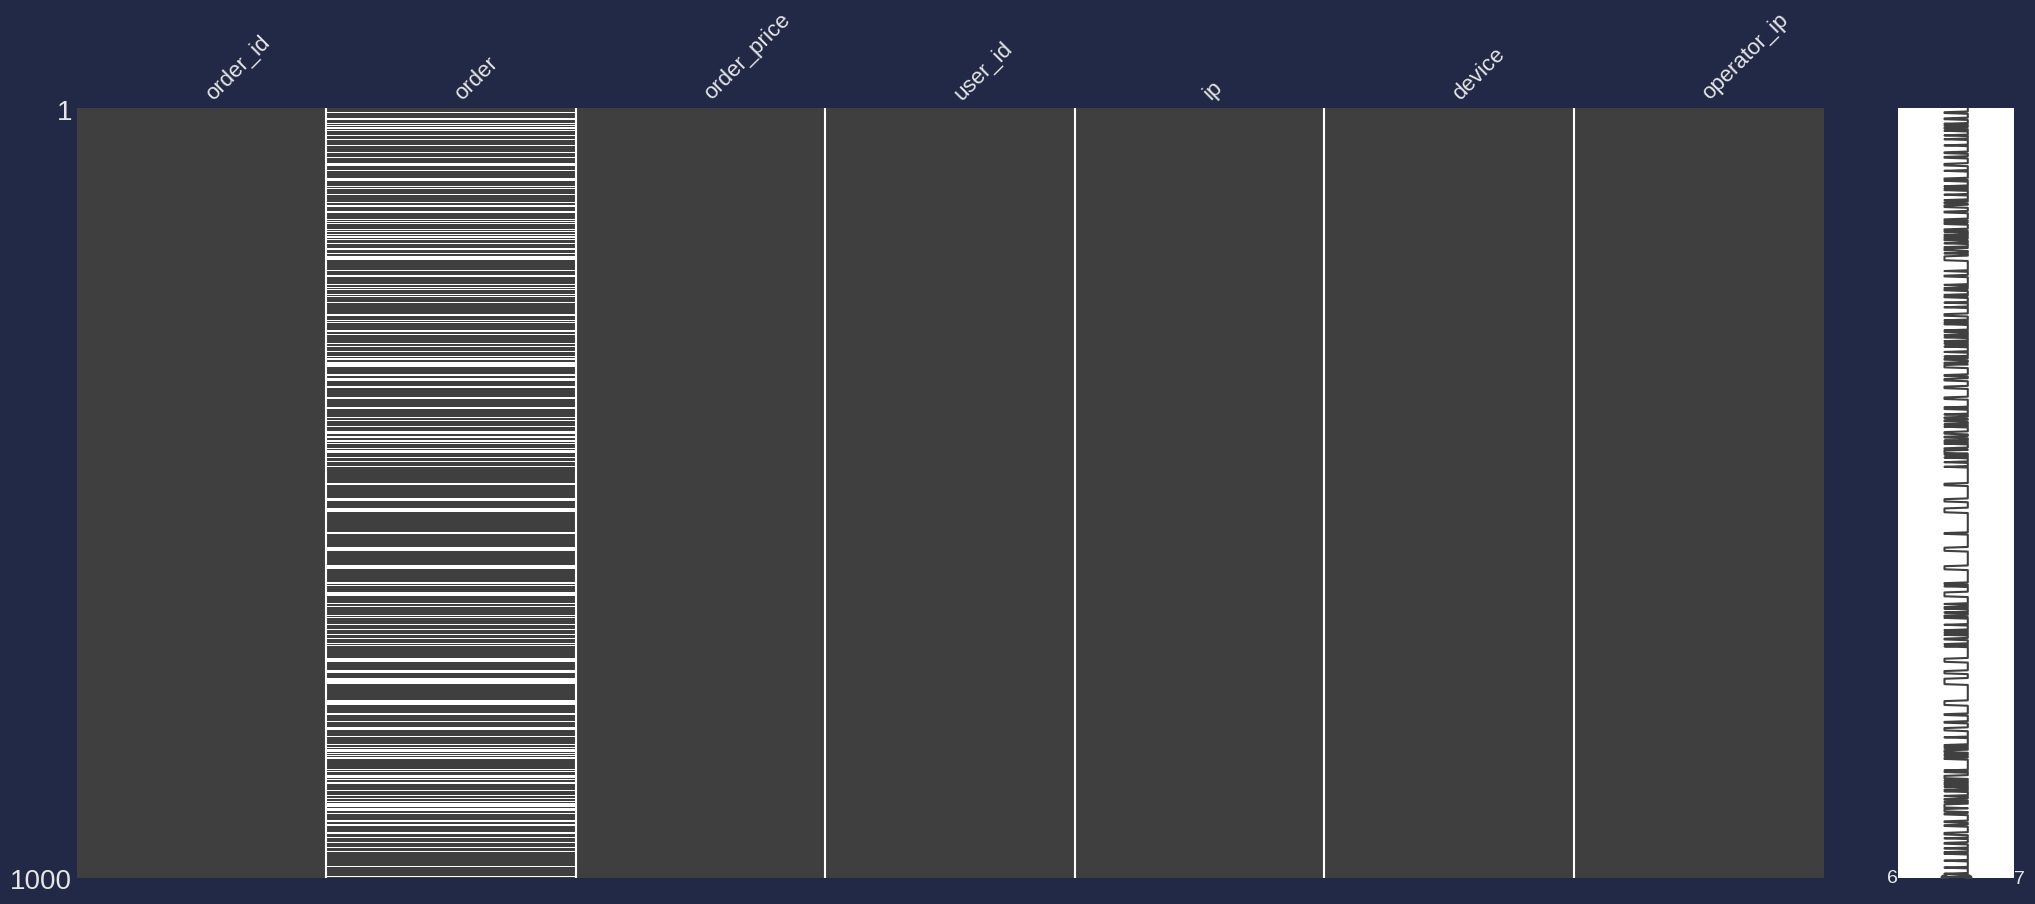

In [ ]:
# Визуализация пропусков

msno.matrix(df_transactions)

plt.show()



---



In [ ]:
# Посмотрим на имеющиеся значения по полю order

df_transactions['order'].value_counts()

,count
order,
Дьябло,58
Гавайская,56
3 пиццы,55
Четыре сыра,54
Пеперони,52
...,...
"Вегетарианская, Мясной микс",1
"Пеперони, Сицилийская",1
"Вегетарианская, Четыре сыра",1




---



**Восстановление пропусков**

**Обоснование решения**


<br>


**1. Определение базовых цен (get_base_prices)**

Логика:

Выбираем только заказы с одной пиццей (без запятых в названии)

Для каждого вида пиццы собираем все встречающиеся цены

Рассчитываем медианную цену для каждого вида (медиана устойчива к выбросам)

Обоснование:

Медиана лучше средней, так как устойчива к аномальным заказам

Используем только одиночные заказы для чистоты определения базовой цены

Результат: словарь {"Пицца": Медианная_цена}

<br>




**2. Сбор статистики (get_user_preferences и get_price_distribution)**

a) Предпочтения пользователей (get_user_preferences):

Считаем, какие пиццы/комбинации чаще заказывал каждый пользователь

Храним в структуре: user_id -> {"Пицца": количество_заказов}


b) Распределение цен (get_price_distribution):

Анализируем, какие заказы (одиночные и комбинации) встречаются по каждой цене

Структура: Цена -> {"Пицца/комбинация": частота}

Обоснование:

Эти данные помогут восстановить пропуски, опираясь на:

Личную историю пользователя

Общие паттерны заказов по каждой цене

<br>



**3. Поиск комбинаций (find_possible_combinations)**
Логика:

Для заданной цены перебираем все возможные комбинации из 1-3 пицц

Проверяем, совпадает ли сумма цен комбинации с целевой ценой

Возвращаем список подходящих вариантов

Пример работы:
Для цены 1090 руб могут найтись комбинации:

"Неаполитанская, Дьябло" (530 + 560 = 1090)

"Мясной микс, Гавайская" (579 + 520 = 1099) → не подойдет

<br>



**4. Восстановление заказов (restore_orders)**
Пошаговая логика:

Шаг 1: Для каждого пропущенного заказа:

Определяем его цену

Ищем все возможные варианты (одиночные и комбинации), которые дают эту цену

Шаг 2: Если вариант один:

Автоматически подставляем его

Шаг 3: Если вариантов несколько:

Проверяем историю пользователя:

Смотрим, какие из возможных вариантов пользователь заказывал раньше

Выбираем самый частый вариант из его истории

Если пользователь не заказывал такие варианты:

Смотрим общую статистику по этой цене

Выбираем случайный вариант, но с учетом частоты встречаемости

Если нет данных вообще:

Берем первый подходящий вариант из возможных


<br>



Шаг 4: Обновляем DataFrame с восстановленными данными

Обоснование подхода:

Приоритет личных предпочтений → больше точности

Статистическое распределение → объективность для новых пользователей

Простое правило для крайних случаев → гарантия заполнения всех пропусков


<br>



**5. Сохранение и вывод результатов**


<br>



**Почему это решение?**


<br>


- Учет контекста:

Личные предпочтения > Общие тенденции

История заказов важнее случайного выбора

- Гибкость:

Работает как с одиночными пиццами, так и с комбинациями

Автоматически адаптируется к разным ценам

- Стабильность:

Всегда дает результат (даже если данные скудные)

Медиана и статистика защищают от аномалий

- Прозрачность


<br>



**Пример работы алгоритма**

Допустим, есть заказ:

Цена: 1090 руб

Пользователь: ID123

История пользователя: часто заказывал "Неаполитанская, Дьябло"

Процесс восстановления:

Найдет комбинации на 1090 руб:

"Неаполитанская, Дьябло" (530+560)

"Маргарита, Вегетарианская, Гавайская" (479+510+520=1509) → не подойдет

Проверит историю пользователя:

Обнаружит, что он часто брал первую комбинацию

Результат: восстановит "Неаполитанская, Дьябло"

In [ ]:
# 1. Функция определения базовых цен
def get_base_prices(data):
    """Определяем базовые цены для каждого вида пиццы"""
    single_pizza_orders = data[~data['order'].str.contains(',', na=False)]

    price_dict = defaultdict(list)
    for _, row in single_pizza_orders.iterrows():
        if pd.notna(row['order']):
            pizza = row['order'].strip()
            price_dict[pizza].append(row['order_price'])

    base_prices = {}
    for pizza, prices in price_dict.items():
        base_prices[pizza] = np.median(prices)

    return base_prices

# 2. Получаем базовые цены и выводим их
base_prices = get_base_prices(df_transactions)
print("Базовые цены для пицц:")
print(pd.DataFrame.from_dict(base_prices, orient='index', columns=['Цена'])
       .sort_values('Цена', ascending=False)
       .to_markdown())

# 3. Функции сбора статистики
def get_user_preferences(data):
    """Какие пиццы/комбинации чаще заказывал каждый пользователь"""
    user_prefs = defaultdict(lambda: defaultdict(int))
    for _, row in data.iterrows():
        if pd.notna(row['order']) and pd.notna(row['user_id']):
            order = row['order'].strip()
            user_prefs[row['user_id']][order] += 1
    return user_prefs

def get_price_distribution(data):
    """Как часто каждая пицца/комбинация встречается по каждой цене"""
    price_dist = defaultdict(lambda: defaultdict(int))
    for _, row in data.iterrows():
        if pd.notna(row['order']):
            order = row['order'].strip()
            price = row['order_price']
            price_dist[price][order] += 1
    return price_dist

# 4. Функция подбора комбинаций пицц
def find_possible_combinations(target_price, base_prices, max_pizzas=3):
    """Находит все возможные комбинации пицц для заданной цены"""
    pizzas = list(base_prices.items())
    combinations_found = []

    for n in range(1, max_pizzas + 1):
        for combo in combinations(pizzas, n):
            names, prices = zip(*combo)
            total = sum(prices)
            if abs(total - target_price) < 1:
                combo_name = ', '.join(names)
                combinations_found.append(combo_name)

    return combinations_found

# 5. Основная функция восстановления
def restore_orders(data, base_prices, user_prefs, price_dist):
    restored = data.copy()

    for idx, row in data.iterrows():
        if pd.isna(row['order']):
            price = row['order_price']
            user_id = row['user_id']

            # Находим все возможные варианты (одиночные и комбинации)
            possible_orders = find_possible_combinations(price, base_prices)

            # Если нашли только один вариант
            if len(possible_orders) == 1:
                restored.at[idx, 'order'] = possible_orders[0]
                continue

            # Если несколько вариантов
            if len(possible_orders) > 1:
                # 1. Проверяем предпочтения пользователя
                user_history = user_prefs.get(user_id, {})
                user_orders = [o for o in possible_orders if o in user_history]

                if user_orders:
                    # Берем самый частый заказ пользователя из возможных
                    chosen = max(user_orders, key=lambda o: user_history[o])
                    restored.at[idx, 'order'] = chosen
                    continue

                # 2. Если пользователь не заказывал такие варианты - смотрим общее распределение
                dist = price_dist.get(price, {})
                possible_dist = {k: v for k, v in dist.items() if k in possible_orders}

                if possible_dist:
                    total = sum(possible_dist.values())
                    # Выбираем случайно с учетом частот
                    orders, counts = zip(*possible_dist.items())
                    probs = [c/total for c in counts]
                    chosen = np.random.choice(orders, p=probs)
                    restored.at[idx, 'order'] = chosen
                    continue

                # 3. Если нет данных вообще - берем первый подходящий вариант
                if possible_orders:
                    restored.at[idx, 'order'] = possible_orders[0]

    return restored

# 6. Собираем статистику и восстанавливаем данные
user_prefs = get_user_preferences(df_transactions)
price_dist = get_price_distribution(df_transactions)
df_restored = restore_orders(df_transactions, base_prices, user_prefs, price_dist)

# 7. Выводим статистику восстановления
print("\nСтатистика восстановления:")
print(f"Всего заказов: {len(df_transactions)}")
print(f"Восстановлено: {df_restored['order'].notna().sum()}")

# 8. Сохраняем результат
df_restored.to_csv(OUTPUT_DIR / 'restored_orders.csv',
                   index=False,
                   encoding='utf-8-sig')
print("\nРезультат сохранен в файл 'restored_orders.csv'")

Базовые цены для пицц:
|                |   Цена |
|:---------------|-------:|
| 3 пиццы        |   1299 |
| Мясной микс    |    579 |
| Дьябло         |    560 |
| Сицилийская    |    545 |
| Неаполитанская |    530 |
| Пеперони       |    530 |
| Гавайская      |    520 |
| Вегетарианская |    510 |
| Четыре сыра    |    499 |
| Маргарита      |    479 |

Статистика восстановления:
Всего заказов: 1000
Восстановлено: 1000

Результат сохранен в файл 'restored_orders.csv'




---



Проверка того, встречаются ли разные цены для пиццы в заказах с одним видом пиццы

In [ ]:
def check_single_pizza_prices(data):
    """
    Проверяет, встречаются ли разные цены для пицц одного вида
    в заказах с одним видом пиццы.

    Параметры:
        data (DataFrame): Исходный датафрейм с колонками 'order' и 'order_price'

    Возвращает:
        dict: Словарь с результатами анализа для каждого вида пиццы
    """

    # 1. Фильтруем заказы с одним видом пиццы (без запятых в названии)
    single_pizza_orders = data[data['order'].str.contains(',') == False]

    # 2. Удаляем пропуски (если есть)
    single_pizza_orders = single_pizza_orders.dropna(subset=['order', 'order_price'])

    # 3. Группируем по названию пиццы и собираем все уникальные цены
    pizza_price_stats = (
        single_pizza_orders.groupby('order')['order_price']
        .agg(['count', 'nunique', 'min', 'max', 'mean'])
        .reset_index()
    )

    # 4. Добавляем колонку с вариативностью цен
    pizza_price_stats['price_variability'] = np.where(
        pizza_price_stats['nunique'] > 1,
        'Разные цены',
        'Одинаковая цена'
    )

    # 5. Сортируем по количеству заказов (для наглядности)
    pizza_price_stats = pizza_price_stats.sort_values('count', ascending=False)

    # 6. Формируем подробный отчет
    result = {}
    for _, row in pizza_price_stats.iterrows():
        pizza_name = row['order']
        result[pizza_name] = {
            'total_orders': row['count'],
            'unique_prices_count': row['nunique'],
            'price_variability': row['price_variability'],
            'min_price': row['min'],
            'max_price': row['max'],
            'mean_price': round(row['mean'], 2),
            'all_prices': sorted(single_pizza_orders[
                single_pizza_orders['order'] == pizza_name
            ]['order_price'].unique().tolist())
        }

    return result

# Применяем функцию к данным
price_analysis = check_single_pizza_prices(df_transactions)

# Выводим результаты
print("Анализ цен для пицц одного вида:")
for pizza, stats in price_analysis.items():
    print(f"\nПицца: {pizza}")
    print(f"  Всего заказов: {stats['total_orders']}")
    print(f"  Уникальных цен: {stats['unique_prices_count']} ({stats['price_variability']})")
    print(f"  Диапазон цен: {stats['min_price']} - {stats['max_price']} руб.")
    print(f"  Средняя цена: {stats['mean_price']} руб.")
    if stats['unique_prices_count'] > 1:
        print(f"  Все варианты цен: {stats['all_prices']}")

Анализ цен для пицц одного вида:

Пицца: Дьябло
  Всего заказов: 58
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 560 - 560 руб.
  Средняя цена: 560.0 руб.

Пицца: Гавайская
  Всего заказов: 56
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 520 - 520 руб.
  Средняя цена: 520.0 руб.

Пицца: 3 пиццы
  Всего заказов: 55
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 1299 - 1299 руб.
  Средняя цена: 1299.0 руб.

Пицца: Четыре сыра
  Всего заказов: 54
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 499 - 499 руб.
  Средняя цена: 499.0 руб.

Пицца: Пеперони
  Всего заказов: 52
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 530 - 530 руб.
  Средняя цена: 530.0 руб.

Пицца: Неаполитанская
  Всего заказов: 50
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 530 - 530 руб.
  Средняя цена: 530.0 руб.

Пицца: Мясной микс
  Всего заказов: 50
  Уникальных цен: 1 (Одинаковая цена)
  Диапазон цен: 579 - 579 руб.
  Средняя цена: 579.0 руб.

Пицца: Вегетарианская




---



Проверка для заказов с ценой 530 руб. (т.к. одинаковая цена для двух видов пиццы)

In [ ]:
# Выбираем все заказы с ценой 530 руб. (из изначальных данных)
orders_530_init = df_transactions[df_transactions['order_price'] == 530]

# Фильтруем только те, которые были изначально заполненными
orders_530_init = orders_530_init[orders_530_init['order'].notna()]

print("Заказы с ценой 530 руб. (только изначально непустые):")
print(orders_530_init['order'].value_counts())
print("--------------------------")
print(orders_530_init['order'].value_counts(normalize=True))

Заказы с ценой 530 руб. (только изначально непустые):
order
Пеперони          52
Неаполитанская    50
Name: count, dtype: int64
--------------------------
order
Пеперони          0.509804
Неаполитанская    0.490196
Name: proportion, dtype: float64


In [ ]:
# Выбираем все заказы с ценой 530 руб.
orders_530 = df_restored[df_restored['order_price'] == 530]

# Фильтруем только те, которые были восстановлены (изначально пустые)
originally_missing = df_transactions.loc[orders_530.index, 'order'].isna()
restored_530 = orders_530.loc[orders_530['order'].notna() & originally_missing]

print("Восстановленные заказы с ценой 530 руб. (изначально пустые):")
print(restored_530['order'].value_counts())
print("--------------------------")
print(restored_530['order'].value_counts(normalize=True))

Восстановленные заказы с ценой 530 руб. (изначально пустые):
order
Неаполитанская    20
Пеперони          19
Name: count, dtype: int64
--------------------------
order
Неаполитанская    0.512821
Пеперони          0.487179
Name: proportion, dtype: float64


In [ ]:
# Проверяем восстановление для цены 530
print("\nРаспределение заказов за 530 руб. (после восстановления - по всем заказам):")
print(df_restored[df_restored['order_price'] == 530]['order'].value_counts())
print("--------------------------")
print(df_restored[df_restored['order_price'] == 530]['order'].value_counts(normalize=True))


Распределение заказов за 530 руб. (после восстановления - по всем заказам):
order
Пеперони          71
Неаполитанская    70
Name: count, dtype: int64
--------------------------
order
Пеперони          0.503546
Неаполитанская    0.496454
Name: proportion, dtype: float64


Как видим, соотношение между видами пицц после восстановления осталось примерно на прежнем уровне.



---



Проверка по ценам

Создадим проверочный столбец с расчетными ценами для сравнения с исходными ценами

In [ ]:
# Функция для расчета проверочной цены
def calculate_expected_price(order, base_prices):
    if pd.isna(order):
        return np.nan

    # Разбиваем заказ на отдельные пиццы
    pizzas = [p.strip() for p in order.split(',')]

    # Считаем общую цену
    total_price = 0
    for pizza in pizzas:
        if pizza in base_prices:
            total_price += base_prices[pizza]
        else:
            # Если пицца не найдена в базовых ценах, возвращаем NaN
            return np.nan

    return total_price

# Добавляем проверочный столбец
df_restored['calculated_price'] = df_restored['order'].apply(
    lambda x: calculate_expected_price(x, base_prices)
)

# Сравниваем цены
df_restored['price_match'] = np.where(
    abs(df_restored['order_price'] - df_restored['calculated_price']) < 1,
    'Совпадает',
    'Не совпадает'
)

# Выводим статистику сравнения
print("\nПроверка соответствия цен:")
print(df_restored['price_match'].value_counts())

# Выводим примеры несовпадений (если есть)
mismatches = df_restored[df_restored['price_match'] == 'Не совпадает']
if not mismatches.empty:
    print("\nПримеры несовпадений цен:")
    print(mismatches[['order', 'order_price', 'calculated_price']].head())
else:
    print("\nВсе цены совпадают с расчетными!")


Проверка соответствия цен:
price_match
Совпадает    1000
Name: count, dtype: int64

Все цены совпадают с расчетными!


In [ ]:
df_restored

,order_id,order,order_price,user_id,ip,device,operator_ip,calculated_price,price_match
0,999,"Мясной микс, 3 пиццы",1878,102475,192.168.66.187,unknown,192.168.215.115,1878.0,Совпадает
1,680,Мясной микс,579,218841,192.168.100.221,mobile,192.168.203.103,579.0,Совпадает
2,687,Мясной микс,579,521065,192.168.100.221,mobile,192.168.202.102,579.0,Совпадает
3,685,Дьябло,560,106146,192.168.100.221,web,192.168.212.112,560.0,Совпадает
4,683,Сицилийская,545,854950,192.168.100.221,mobile,192.168.217.117,545.0,Совпадает
...,...,...,...,...,...,...,...,...,...
995,917,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.216.116,499.0,Совпадает
996,919,Четыре сыра,499,957570,192.168.42.163,mobile,192.168.205.105,499.0,Совпадает
997,918,"Дьябло, Гавайская",1080,957570,192.168.42.163,unknown,192.168.205.105,1080.0,Совпадает
998,948,Дьябло,560,976203,192.168.79.200,unknown,192.168.213.113,560.0,Совпадает


In [ ]:
df_restored = df_restored.drop(columns=['price_match'])



---



Сравнение топ-10 популярных заказов пицц до и после восстановления данных

In [ ]:
# Сравнение топ-10 популярных заказов пицц до и после восстановления данных
original_top = df_transactions[df_transactions['order'].notna()]['order'].\
value_counts().head(10)
restored_top = df_restored[df_transactions['order'].isna()]['order'].\
value_counts().head(10)

print("Топ-10 оригинальных заказов:")
print(original_top)
print("\nТоп-10 восстановленных заказов:")
print(restored_top)

Топ-10 оригинальных заказов:
order
Дьябло            58
Гавайская         56
3 пиццы           55
Четыре сыра       54
Пеперони          52
Мясной микс       50
Неаполитанская    50
Вегетарианская    40
Сицилийская       38
Маргарита         37
Name: count, dtype: int64

Топ-10 восстановленных заказов:
order
Маргарита         24
Дьябло            23
Неаполитанская    20
Пеперони          19
Гавайская         19
Вегетарианская    18
3 пиццы           18
Сицилийская       16
Четыре сыра       14
Мясной микс       14
Name: count, dtype: int64


In [ ]:
plt.style.use('cyberpunk')

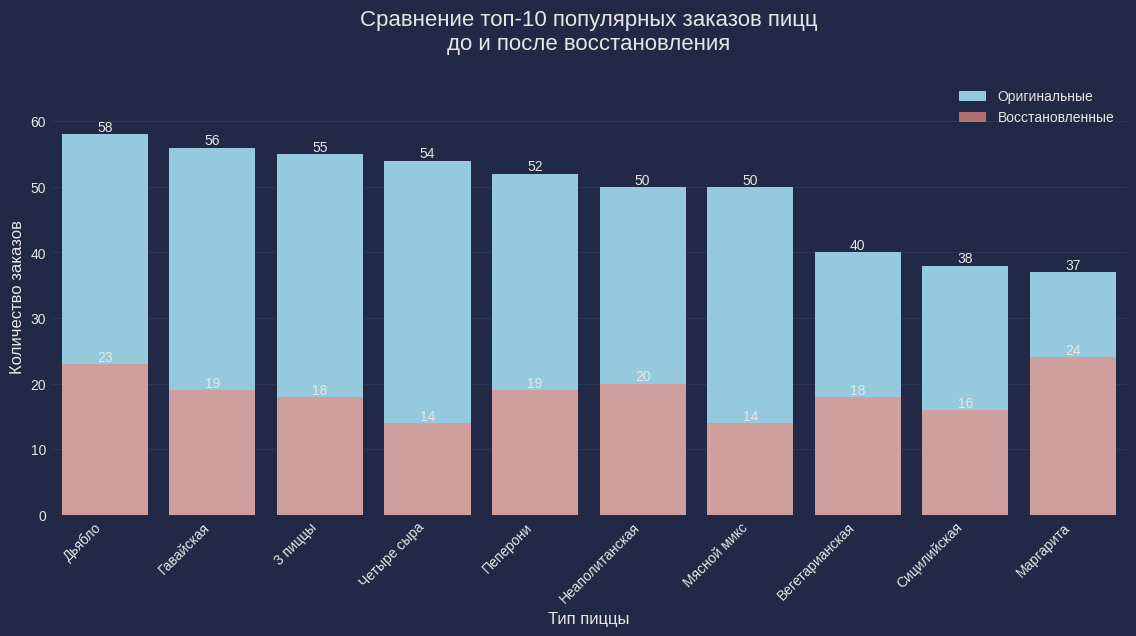

In [ ]:
# Создаем DataFrame для визуализации
top_combined = pd.DataFrame({
    'Оригинальные заказы': original_top,
    'Восстановленные заказы': restored_top
}).fillna(0)

# Сортируем по оригинальным заказам
top_combined = top_combined.sort_values('Оригинальные заказы', ascending=False)

# Создаем фигуру
plt.figure(figsize=(12, 7))

# График для оригинальных заказов
ax = sns.barplot(
    x=top_combined.index,
    y=top_combined['Оригинальные заказы'],
    color='skyblue',
    label='Оригинальные'
)

# График для восстановленных заказов
sns.barplot(
    x=top_combined.index,
    y=top_combined['Восстановленные заказы'],
    color='salmon',
    label='Восстановленные',
    alpha=0.7,
    ax=ax
)

# Настройки графика
plt.title('Сравнение топ-10 популярных заказов пицц\nдо и после восстановления',
          fontsize=16, pad=20)
plt.xlabel('Тип пиццы', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend()

# Автоматическая подгонка layout с дополнительными отступами
plt.tight_layout(pad=3)

# Добавляем значения на столбцы с динамическим позиционированием
for i, (orig, rest) in enumerate(zip(top_combined['Оригинальные заказы'],
                                     top_combined['Восстановленные заказы'])):
    y_pos = max(orig, rest) + (0.05 * max(top_combined['Оригинальные заказы']))
    if orig > 0:
        ax.text(i, orig, str(int(orig)),
                ha='center', va='bottom', fontsize=10)
    if rest > 0:
        ax.text(i, rest, str(int(rest)),
                ha='center', va='bottom', fontsize=10)

# Увеличиваем верхний отступ графика
ax.set_ylim(top=max(top_combined.max()) * 1.15)  # +15% места сверху

plt.show()

Как видим, выраженного дисбаланса между изначальными и восстановленными данными не наблюдается.



---



Кросс-валидация на известных данных

In [ ]:
# Искусственно скрываем часть известных данных и проверяем восстановление
known_data = df_transactions[df_transactions['order'].notna()].copy()
train, test = train_test_split(known_data, test_size=0.2, random_state=42)

# Скрываем заказы в тестовой выборке
test_hidden = test.copy()
test_hidden['order'] = np.nan

# Восстанавливаем
test_restored = restore_orders(test_hidden, base_prices, user_prefs, price_dist)

# Считаем точность
accuracy = (test['order'] == test_restored['order']).mean()
print(f"Точность восстановления на известных данных: {accuracy:.2%}")

Точность восстановления на известных данных: 79.59%


Точность восстановления приемлемая.



---



Проверка логики комбинаций

In [ ]:
# Ищем нелогичные комбинации (например, повторяющиеся пиццы)
def find_weird_combinations(orders):
    weird = []
    for order in orders.dropna():
        pizzas = [p.strip() for p in order.split(',')]
        if len(pizzas) != len(set(pizzas)):
            weird.append(order)
    return pd.Series(weird).value_counts()

weird_combos = find_weird_combinations(df_restored['order'])
if not weird_combos.empty:
    print("\nНайдены странные комбинации:")
    print(weird_combos)
else:
    print("\nВсе комбинации выглядят логично.")


Все комбинации выглядят логично.




---



# **ЗАДАНИЕ 2**

**Определи возможных злоумышленников и обоснуй свой выбор**

Анализ данных для выявления злоумышленников

In [ ]:
# Распределение IP-адресов по количеству заказов
df_transactions['ip'].value_counts()

,count
ip,
192.168.47.168,222
192.168.27.148,182
192.168.4.125,75
192.168.96.217,75
192.168.84.205,75
...,...
192.168.8.129,1
192.168.36.157,1
192.168.57.178,1


In [ ]:
# Топ IP-адресов по количеству заказов
ip_counts = df_transactions['ip'].value_counts()
print(ip_counts.head(10))

ip
192.168.47.168     222
192.168.27.148     182
192.168.4.125       75
192.168.96.217      75
192.168.84.205      75
192.168.69.190      24
192.168.13.134      24
192.168.29.150      19
192.168.100.221     19
192.168.77.198      19
Name: count, dtype: int64


In [ ]:
# Выделим IP-адреса с аномально большим числом заказов
ip_suspicious = ip_counts[ip_counts > 50].index.tolist()

print("Подозрительные IP:", ip_suspicious)

Подозрительные IP: ['192.168.47.168', '192.168.27.148', '192.168.4.125', '192.168.96.217', '192.168.84.205']


Как видим, есть IP-адреса с подозрительно большим количеством заказов - это 192.168.47.168 и 192.168.27.148

In [ ]:
# Распределение пользователей по количеству заказов
df_transactions['user_id'].value_counts()

,count
user_id,
924197,5
142237,5
340644,5
796365,5
853594,5
...,...
693875,1
462358,1
332990,1


In [ ]:
# Топ пользователей по количеству заказов
user_counts = df_transactions['user_id'].value_counts()
print(user_counts.head(20))

user_id
924197    5
142237    5
340644    5
796365    5
853594    5
106146    5
397949    5
720230    4
523106    4
736402    4
120373    3
957570    3
912391    3
690831    3
781209    3
908857    3
823236    3
363028    3
532741    3
225284    3
Name: count, dtype: int64


Как видим, есть пользователи с большим числом заказом (относительно основной массы пользователей).

In [ ]:
# Распределение IP-адресов операторов по количеству заказов
operators_counts = df_transactions['operator_ip'].value_counts()

operators_counts

,count
operator_ip,
192.168.212.112,63
192.168.211.111,59
192.168.216.116,58
192.168.206.106,58
192.168.91.212,55
192.168.85.206,55
192.168.203.103,55
192.168.215.115,54
192.168.205.105,54


In [ ]:
# Выделим IP-адреса операторов с наиболее большим числом заказов
operator_ip_suspicious = operators_counts[operators_counts >= 55].index.tolist()

print("Подозрительные IP операторов:", operator_ip_suspicious)

Подозрительные IP операторов: ['192.168.212.112', '192.168.211.111', '192.168.216.116', '192.168.206.106', '192.168.91.212', '192.168.85.206', '192.168.203.103']


Есть довольно большой размах в количестве заказов, обрабатываемых каждым оператором.



---



Анализ распределения цен

Проверим, нет ли аномалий в ценах

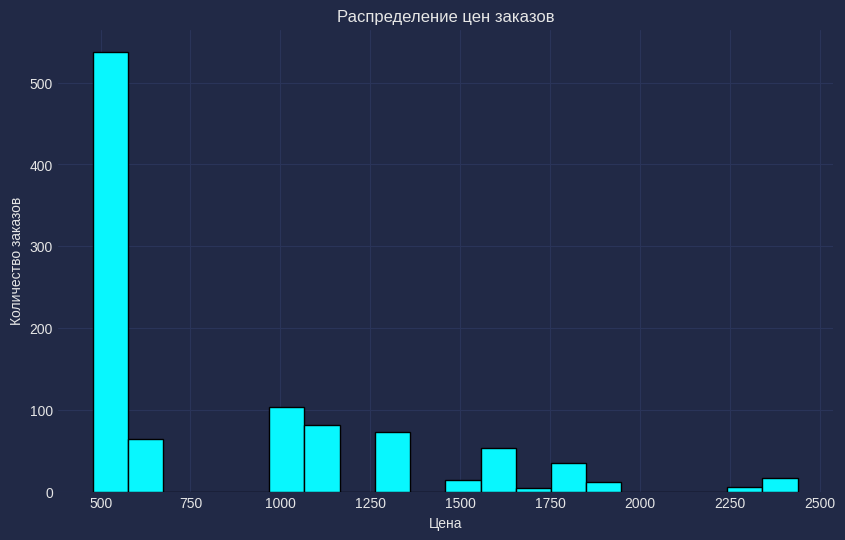

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df_transactions['order_price'], bins=20, edgecolor='k')
plt.title('Распределение цен заказов')
plt.xlabel('Цена')
plt.ylabel('Количество заказов')
plt.show()

Как видим, хотя большинство заказов сконцентрированы в интервале 500-600 (самые низкие цены), аномально высоких по цене заказов всё же не наблюдается. Максимальные цены - в районе 2500 - вполне реальны.



---



Распределение пустых заказов по пользователям

In [ ]:
# Определение "пустых" заказов
empty_orders = df_transactions['order'].isna() | (df_transactions['order'] == '')

# Подсчет количества "пустых" заказов для каждого пользователя
empty_orders_distribution = df_transactions[empty_orders].groupby('user_id').size()

empty_orders_distribution

,0
user_id,
104322,1
105838,1
118675,1
120373,1
122608,1
...,...
948406,1
955301,1
957570,1


По каждому пользователю - не более одного потерянного заказа.



---



Распределение пустых заказов по операторам

In [ ]:
empty_orders_distribution = (
    df_transactions[df_transactions['order'].isna()]
    .groupby('operator_ip')
    .size()
    .sort_values(ascending=False)
    .reset_index(name='empty_orders_count')
)

empty_orders_distribution

,operator_ip,empty_orders_count
0,192.168.203.103,18
1,192.168.208.108,17
2,192.168.216.116,17
3,192.168.205.105,16
4,192.168.206.106,16
5,192.168.204.104,14
6,192.168.91.212,14
7,192.168.215.115,14
8,192.168.85.206,14
9,192.168.202.102,13




---



Пересечения между IP-адресами пользователей и операторов

In [ ]:
# Находим строки, где IP пользователя совпадает с IP оператора
same_ip_records = df_transactions[df_transactions['ip'] == df_transactions['operator_ip']]

if not same_ip_records.empty:
    print("Найдены записи, где IP пользователя совпадает с IP оператора:")
    print(same_ip_records[['user_id', 'ip', 'operator_ip']])
else:
    print("Совпадений IP пользователей и операторов не найдено.")

Совпадений IP пользователей и операторов не найдено.




---



Как распределялись заказы пользователей по типам устройств, ip и операторам

In [ ]:
# Создание сводной таблицы
pivot_table = pd.pivot_table(
    df_transactions,
    values='order_id',
    index='user_id',
    columns='device',
    aggfunc='count',
    fill_value=0
)

# Добавление столбца с общим числом заказов
pivot_table['total_orders'] = pivot_table.sum(axis=1)

# Сортировка по убыванию общего числа заказов
pivot_table = pivot_table.sort_values(by='total_orders', ascending=False)

styled_table = (pivot_table
                .head(20)
                .style
                .background_gradient(cmap='Blues'))

display(styled_table)

device,mobile,unknown,web,total_orders
user_id,,,,
796365,1,2,2,5
397949,1,3,1,5
106146,2,1,2,5
924197,3,1,1,5
142237,1,0,4,5
853594,2,0,3,5
340644,0,2,3,5
736402,1,0,3,4
523106,0,4,0,4


Как видим, пользователи с максимальным числом заказов использовали разные типы устройств для разных заказов (причем все три типа устройств), что может быть потенциально подозрительным (например, попытка "замести следы"). Степень подозрительности возрастает, если применяется устройство с типом "unknown". Таким образом, отнесем к подозрительным первых четырех пользователей (максимальное число заказов, разные типы устройств, причем все три типа, включая подозрительный "unknown").

In [ ]:
# Извлечение номеров первых четырех пользователей
users_suspicious = pivot_table.index[:4].tolist()

print("Наиболее подозрительные пользователи:", users_suspicious)

Наиболее подозрительные пользователи: [796365, 397949, 106146, 924197]


In [ ]:
# Фильтрация данных для подозрительных пользователей - по ip
suspicious_data = df_transactions[df_transactions['user_id'].isin(users_suspicious)]

# Создание сводной таблицы для подозрительных пользователей
user_ip_summary = suspicious_data.groupby(['user_id', 'ip']).agg(
    total_orders=pd.NamedAgg(column='order_id', aggfunc='count')
).reset_index()

# Подсчет общего количества заказов по каждому IP-адресу для всех пользователей
ip_total_orders = df_transactions.groupby('ip').agg(
    total_orders_ip=pd.NamedAgg(column='order_id', aggfunc='count')
).reset_index()

# Объединение данных
user_ip_summary = user_ip_summary.merge(ip_total_orders, on='ip', how='left')

# Переименование столбцов для ясности
user_ip_summary.columns = ['user_id', 'ip', \
                           'suspicious_user_total_orders', 'all_users_total_orders']

styled_table_2 = user_ip_summary.style.background_gradient(
    subset=['all_users_total_orders'],
    cmap='Blues',
    axis=0
)

display(styled_table_2)

,user_id,ip,suspicious_user_total_orders,all_users_total_orders
0,106146,192.168.100.221,5,19
1,397949,192.168.29.150,5,19
2,796365,192.168.47.168,5,222
3,924197,192.168.84.205,5,75


Каждый подозрительный пользователь заказвал только с одного ip.
Но ip пользователя 796365 - редордсмен (топ-1) по массовости (по количеству общих заказов всех пользователей). ip пользователя 924197 также с большим общим числом заказов. По оставшимся ip общее количество заказов тоже довольно большое.



---



In [ ]:
# Создание сводной таблицы для подозрительных пользователей - по ip операторов
user_ip_summary = suspicious_data.groupby(['user_id', 'operator_ip']).agg(
    total_orders=pd.NamedAgg(column='order_id', aggfunc='count')
).reset_index()

# Подсчет общего количества заказов по каждому IP-адресу для всех пользователей
ip_total_orders = df_transactions.groupby('operator_ip').agg(
    total_orders_ip=pd.NamedAgg(column='order_id', aggfunc='count')
).reset_index()

# Объединение данных
user_ip_summary = user_ip_summary.merge(ip_total_orders, on='operator_ip', how='left')

# Переименование столбцов для ясности
user_ip_summary.columns = ['user_id', 'operator_ip', \
                           'suspicious_user_total_orders', 'all_users_total_orders']

styled_table_2 = user_ip_summary.style.background_gradient(
    subset=['all_users_total_orders'],
    cmap='Blues',
    axis=0
)

display(styled_table_2)

,user_id,operator_ip,suspicious_user_total_orders,all_users_total_orders
0,106146,192.168.204.104,1,51
1,106146,192.168.206.106,1,58
2,106146,192.168.208.108,1,42
3,106146,192.168.212.112,1,63
4,106146,192.168.216.116,1,58
5,397949,192.168.204.104,1,51
6,397949,192.168.205.105,1,54
7,397949,192.168.209.109,1,38
8,397949,192.168.218.118,1,37
9,397949,192.168.46.167,1,42


Как видим, все заказы каждого наиболее подозрительного пользователя производились на разные ip операторов (кроме случая, когда с ip 192.168.214.114 было два заказа), что также выглядит как фактор риска. И все эти ip операторов - в целом с большим количеством заказов от пользователей.
Самые массовые ip операторов по общему количеству заказов - у пользователей 106146, 796365 и 924197.

In [ ]:
operator_ip_suspicious

['192.168.212.112',
 '192.168.211.111',
 '192.168.216.116',
 '192.168.206.106',
 '192.168.91.212',
 '192.168.85.206',
 '192.168.203.103']

Как видим, с выделенными наиболее подозрительными пользователями контактировали выделенные ранее операторы с большим количеством заказов - с ip 192.168.212.112, 192.168.206.106, 192.168.216.116.



---



Заказы с наиболее подозрительных ip пользователей по операторам

In [ ]:
ip_suspicious

['192.168.47.168',
 '192.168.27.148',
 '192.168.4.125',
 '192.168.96.217',
 '192.168.84.205']

In [ ]:
# Фильтрация данных для подозрительных IP-адресов пользователей
suspicious_data = df_transactions[df_transactions['ip'].isin(ip_suspicious)]

# Создание сводной таблицы
ip_summary = suspicious_data.groupby(['ip', 'operator_ip']).agg(
    total_orders=pd.NamedAgg(column='order_id', aggfunc='count'),
    user_ids=pd.NamedAgg(column='user_id', aggfunc=lambda x: list(x.unique()))
).reset_index()

# Добавление столбца с подозрительными user_id
ip_summary['suspicious_user_ids'] = ip_summary['user_ids'].\
apply(lambda x: [uid for uid in x if uid in users_suspicious])

# Сортировка по убыванию общего числа заказов
ip_summary = ip_summary.sort_values(by='total_orders', ascending=False)

ip_summary.head(60)

,ip,operator_ip,total_orders,user_ids,suspicious_user_ids
41,192.168.47.168,192.168.203.103,18,"[552578, 796365, 887871, 701796, 263237, 30161...",[796365]
52,192.168.47.168,192.168.214.114,17,"[592285, 436869, 796365, 554538, 610829, 93813...",[796365]
10,192.168.27.148,192.168.212.112,16,"[339719, 151172, 656700, 617454, 813290, 59140...",[]
19,192.168.27.148,192.168.91.212,15,"[453302, 488246, 193049, 122358, 866871, 76836...",[]
50,192.168.47.168,192.168.212.112,14,"[661593, 606364, 386626, 796365, 447288, 20061...",[796365]
49,192.168.47.168,192.168.211.111,13,"[534693, 123601, 566409, 716550, 498567, 25230...",[]
55,192.168.47.168,192.168.217.117,13,"[586795, 337684, 438788, 961306, 719491, 57955...",[]
45,192.168.47.168,192.168.207.107,13,"[862689, 231931, 370324, 401955, 262399, 53631...",[]
53,192.168.47.168,192.168.215.115,13,"[971074, 264158, 511221, 216372, 548076, 40284...",[]
58,192.168.47.168,192.168.85.206,13,"[513611, 323845, 435515, 790230, 374456, 65348...",[]


В топе общего количества заказов по пересечениям наиболее подозрительных ip пользователей и операторов просматриваются и потенциально подозрительные операторы (192.168.212.112, 192.168.206.106, 192.168.216.116).

Здесь и выявленные ранее потенциально подозрительные пользователи - в особенности 796365. Также здесь есть и пользователь 924197.



---



ТОП пользователей по подозрительным операторам

In [ ]:
suspect_ops = df_transactions[df_transactions['operator_ip'].\
                              isin(['192.168.212.112', '192.168.206.106', '192.168.216.116'])]
suspect_ops['user_id'].value_counts().head(20)  # топ пользователей у этих операторов

,count
user_id,
340644,4
142237,3
106146,3
853594,2
492904,2
908857,2
104322,1
896258,1
642356,1


Отметим, что здесь снова пользователь 106146.



---



*Дополнительные визуализации взаимосвязей пользователей, ip пользователей и ip операторов*

Тепловая карта по количеству заказов: взаимосвязи пользователей (топ-20) и IP пользователей (топ-20) (с выделением подозрительных элементов)

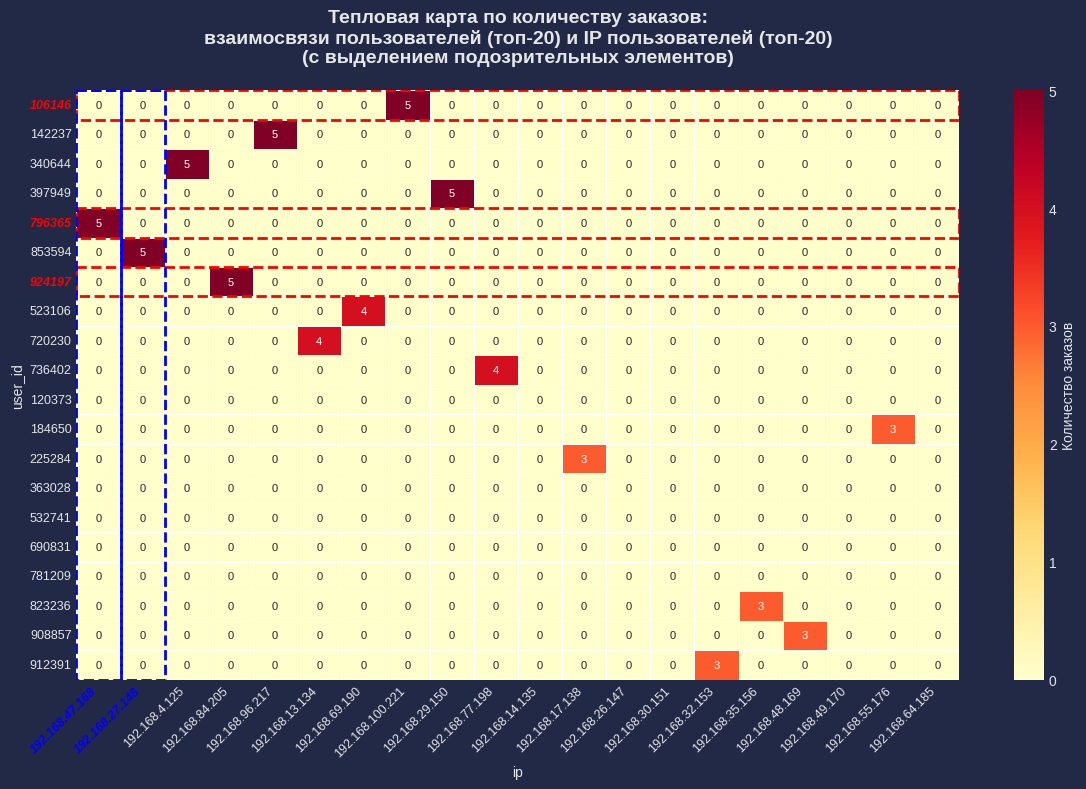

In [ ]:
# Подготовка данных - группируем по user_id и ip
user_ip_counts = df_transactions.groupby(['user_id', 'ip']).size().\
unstack(fill_value=0)

# Выбираем топ-20 пользователей и топ-20 IP пользователей
top_users = user_ip_counts.sum(axis=1).nlargest(20).index
top_ips = user_ip_counts.sum(axis=0).nlargest(20).index

# Фильтруем данные
heatmap_data = user_ip_counts.loc[top_users, top_ips]

# Создаем фигуру
plt.figure(figsize=(12, 8))

# Создаем heatmap
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=.5,
    annot_kws={"size": 8},
    cbar_kws={'label': 'Количество заказов'}
)

# Список подозрительных пользователей и IP пользователей
suspect_users = ['796365', '106146', '924197']
suspect_ips = ['192.168.47.168', '192.168.27.148']

# Получаем текущие подписи
y_labels = ax.get_yticklabels()
x_labels = ax.get_xticklabels()

# Изменяем стиль подписей
for label in y_labels:
    if label.get_text() in suspect_users:
        label.set_color('red')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

for label in x_labels:
    if label.get_text() in suspect_ips:
        label.set_color('blue')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

# Поворачиваем подписи IP
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)

# Добавляем заголовок
plt.title('Тепловая карта по количеству заказов:\n\
взаимосвязи пользователей (топ-20) и IP пользователей (топ-20)\n\
(с выделением подозрительных элементов)',
          pad=20,
          fontsize=14,
          fontweight='bold')

# Добавляем прямоугольники для выделения подозрительных элементов
for i, user in enumerate(heatmap_data.index):
    if str(user) in suspect_users:
        ax.add_patch(plt.Rectangle((0, i), len(heatmap_data.columns), 1,
                     fill=False, edgecolor='red', lw=2, linestyle='--'))

for j, ip in enumerate(heatmap_data.columns):
    if ip in suspect_ips:
        ax.add_patch(plt.Rectangle((j, 0), 1, len(heatmap_data.index),
                     fill=False, edgecolor='blue', lw=2, linestyle='--'))

# Улучшаем layout
plt.tight_layout()
plt.show()

Как видим, в целом прослеживается, что пользователи с наибольшим числом заказов совершали заказы с ip, для которых также характерно наибольшее количество заказов. Это тенденция верна и в отношении подозрительных пользователей и подозрительных ip.



---



Тепловая карта по количеству заказов: взаимосвязи пользователей (топ-20) и IP операторов (топ-20) (с выделением подозрительных элементов)

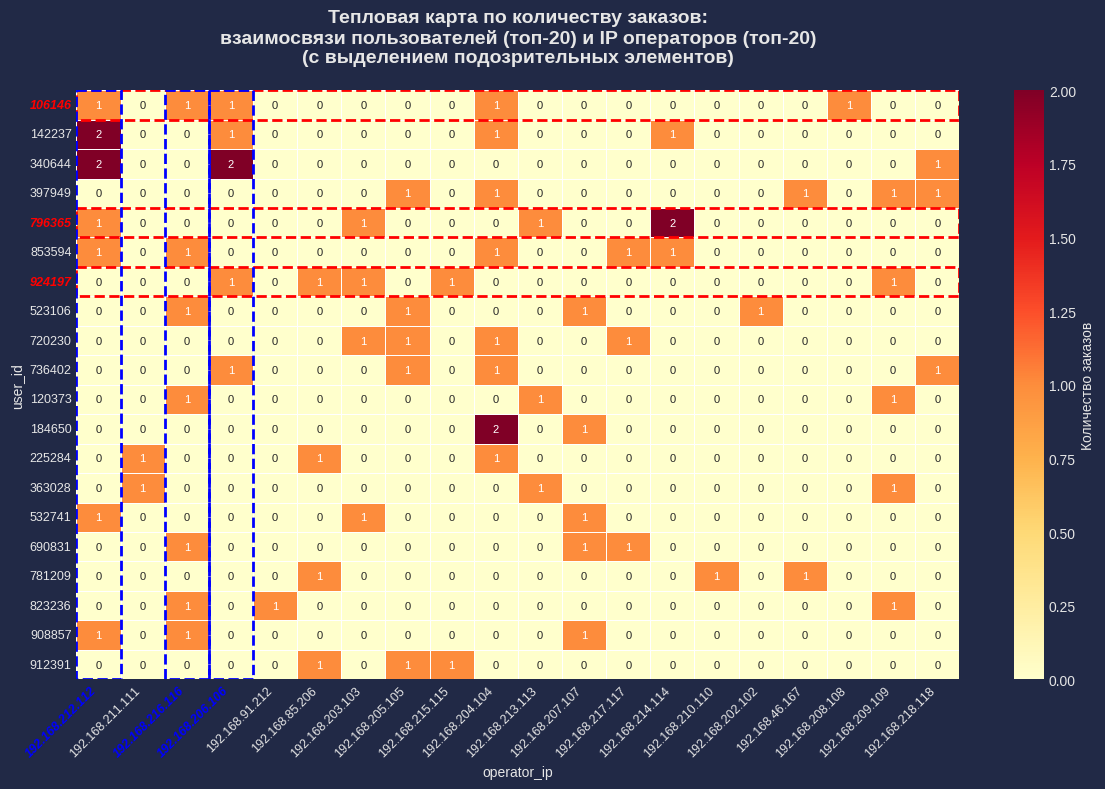

In [ ]:
# Подготовка данных - группируем по user_id и operator_ip
user_operator_counts = df_transactions.groupby(['user_id', 'operator_ip']).\
size().unstack(fill_value=0)

# Выбираем топ-20 пользователей и топ-20 IP операторов
top_users = user_operator_counts.sum(axis=1).nlargest(20).index
top_operator_ips = user_operator_counts.sum(axis=0).nlargest(20).index

# Фильтруем данные
heatmap_data = user_operator_counts.loc[top_users, top_operator_ips]

# Создаем фигуру
plt.figure(figsize=(12, 8))

# Создаем heatmap
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=.5,
    annot_kws={"size": 8},
    cbar_kws={'label': 'Количество заказов'}
)

# Список подозрительных пользователей и IP операторов
suspect_users = ['796365', '106146', '924197']
suspect_operator_ips = ['192.168.212.112', '192.168.206.106', '192.168.216.116']

# Получаем текущие подписи
y_labels = ax.get_yticklabels()
x_labels = ax.get_xticklabels()

# Изменяем стиль подписей
for label in y_labels:
    if label.get_text() in suspect_users:
        label.set_color('red')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

for label in x_labels:
    if label.get_text() in suspect_operator_ips:
        label.set_color('blue')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

# Поворачиваем подписи IP
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)

# Добавляем заголовок
plt.title('Тепловая карта по количеству заказов:\n\
взаимосвязи пользователей (топ-20) и IP операторов (топ-20)\n\
(с выделением подозрительных элементов)',
          pad=20,
          fontsize=14,
          fontweight='bold')

# Добавляем прямоугольники для выделения подозрительных элементов
for i, user in enumerate(heatmap_data.index):
    if str(user) in suspect_users:
        ax.add_patch(plt.Rectangle((0, i), len(heatmap_data.columns), 1,
                     fill=False, edgecolor='red', lw=2, linestyle='--'))

for j, ip in enumerate(heatmap_data.columns):
    if ip in suspect_operator_ips:
        ax.add_patch(plt.Rectangle((j, 0), 1, len(heatmap_data.index),
                     fill=False, edgecolor='blue', lw=2, linestyle='--'))

# Улучшаем layout
plt.tight_layout()
plt.show()

Как видим, в целом прослеживается, что пользователи с наибольшим числом заказов совершали заказы у операторов с ip, для которых также характерно наибольшее количество заказов. Это тенденция верна и в отношении подозрительных пользователей и подозрительных ip операторов.



---



Тепловая карта по количеству заказов: IP пользователей (топ-20) и IP операторов (топ-20) (с выделением подозрительных элементов)

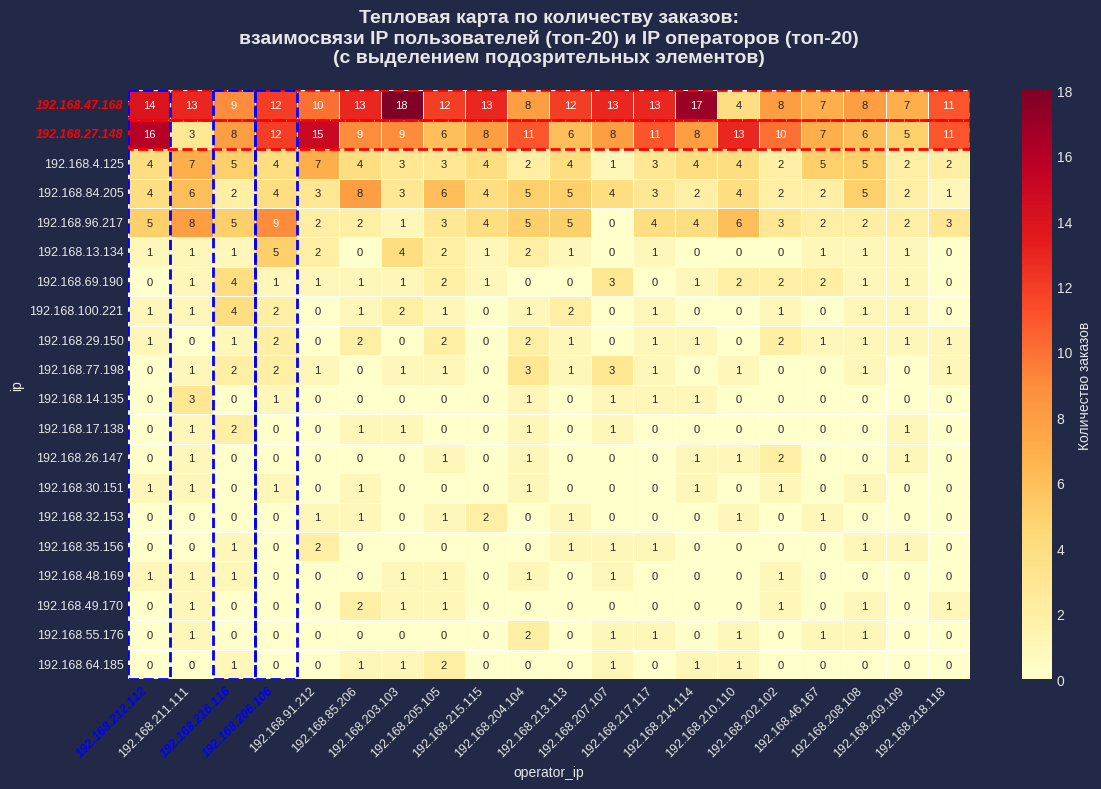

In [ ]:
# Подготовка данных - группируем по ip и operator_ip
ip_operator_counts = df_transactions.groupby(['ip', 'operator_ip']).size().\
unstack(fill_value=0)

# Выбираем топ-20 ip пользователей и топ-20 IP операторов
top_ips = ip_operator_counts.sum(axis=1).nlargest(20).index
top_operator_ips = ip_operator_counts.sum(axis=0).nlargest(20).index

# Фильтруем данные
heatmap_data = ip_operator_counts.loc[top_ips, top_operator_ips]

# Создаем фигуру
plt.figure(figsize=(12, 8))

# Создаем heatmap
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=.5,
    annot_kws={"size": 8},
    cbar_kws={'label': 'Количество заказов'}
)

# Список подозрительных IP пользователей и IP операторов
suspect_ips = ['192.168.47.168', '192.168.27.148']
suspect_operator_ips = ['192.168.212.112', '192.168.206.106', '192.168.216.116']

# Получаем текущие подписи
y_labels = ax.get_yticklabels()
x_labels = ax.get_xticklabels()

# Изменяем стиль подписей
for label in y_labels:
    if label.get_text() in suspect_ips:
        label.set_color('red')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

for label in x_labels:
    if label.get_text() in suspect_operator_ips:
        label.set_color('blue')
        label.set_weight('bold')
        label.set_fontsize(10)
        label.set_style('italic')

# Поворачиваем подписи IP
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)

# Добавляем заголовок
plt.title('Тепловая карта по количеству заказов:\n\
взаимосвязи IP пользователей (топ-20) и IP операторов (топ-20)\n\
(с выделением подозрительных элементов)',
          pad=20,
          fontsize=14,
          fontweight='bold')

# Добавляем прямоугольники для выделения подозрительных элементов
for i, user in enumerate(heatmap_data.index):
    if str(user) in suspect_ips:
        ax.add_patch(plt.Rectangle((0, i), len(heatmap_data.columns), 1,
                     fill=False, edgecolor='red', lw=2, linestyle='--'))

for j, ip in enumerate(heatmap_data.columns):
    if ip in suspect_operator_ips:
        ax.add_patch(plt.Rectangle((j, 0), 1, len(heatmap_data.index),
                     fill=False, edgecolor='blue', lw=2, linestyle='--'))

# Улучшаем layout
plt.tight_layout()
plt.show()

Как видим, довольно явно прослеживается, что ip пользователей с наибольшим числом заказов были задействованы при совершении заказов у операторов с ip, для которых также характерно наибольшее количество заказов. Это тенденция верна и в отношении подозрительных ip пользователей и подозрительных ip операторов.



---



Рассмотрим подробнее заказы по выделенным наиболее подозрительным пользователям.

In [ ]:
df_transactions[df_transactions['user_id'] == 106146]

,order_id,order,order_price,user_id,ip,device,operator_ip
3,685,Дьябло,560,106146,192.168.100.221,web,192.168.212.112
7,696,Пеперони,530,106146,192.168.100.221,unknown,192.168.208.108
10,689,Четыре сыра,499,106146,192.168.100.221,mobile,192.168.216.116
11,684,Четыре сыра,499,106146,192.168.100.221,mobile,192.168.204.104
17,695,"Вегетарианская, Дьябло",1070,106146,192.168.100.221,web,192.168.206.106


Если предположить, что order_id	связан со временем, то заказы совершены практически друг за другом, что выглядит особенно подозрительно.

Видим также связь со всеми тремя наиболее подозрительными операторами.

In [ ]:
df_transactions[df_transactions['user_id'] == 796365]

,order_id,order,order_price,user_id,ip,device,operator_ip
494,222,Дьябло,560,796365,192.168.47.168,web,192.168.203.103
525,216,Неаполитанская,530,796365,192.168.47.168,web,192.168.212.112
526,214,Неаполитанская,530,796365,192.168.47.168,unknown,192.168.214.114
599,202,Маргарита,479,796365,192.168.47.168,mobile,192.168.213.113
659,221,NaN,1090,796365,192.168.47.168,unknown,192.168.214.114


Если предположить, что order_id	связан со временем, то заказы совершены практически друг за другом, что выглядит особенно подозрительно.

In [ ]:
df_transactions[df_transactions['user_id'] == 924197]

,order_id,order,order_price,user_id,ip,device,operator_ip
914,478,Мясной микс,579,924197,192.168.84.205,unknown,192.168.85.206
917,408,Дьябло,560,924197,192.168.84.205,mobile,192.168.209.109
960,479,NaN,1878,924197,192.168.84.205,web,192.168.206.106
962,472,"Сицилийская, 3 пиццы",1844,924197,192.168.84.205,mobile,192.168.203.103
966,466,"Гавайская, Маргарита, Дьябло",1559,924197,192.168.84.205,mobile,192.168.215.115


Если предположить, что order_id	связан со временем, то заказы совершены практически друг за другом, что выглядит особенно подозрительно.

Видим также связь с одним из наиболее подозрительных операторов.



---



Рассмотрим подробнее заказы по выделенным наиболее подозрительным операторам.

In [ ]:
df_transactions[df_transactions['operator_ip'] == '192.168.212.112']

,order_id,order,order_price,user_id,ip,device,operator_ip
3,685,Дьябло,560,106146,192.168.100.221,web,192.168.212.112
26,853,NaN,1844,104322,192.168.65.186,mobile,192.168.212.112
36,995,Неаполитанская,530,136888,192.168.72.193,mobile,192.168.212.112
37,875,"Гавайская, Маргарита",999,907417,192.168.74.195,mobile,192.168.212.112
40,611,NaN,989,660899,192.168.96.217,web,192.168.212.112
...,...,...,...,...,...,...,...
909,407,NaN,579,398949,192.168.84.205,mobile,192.168.212.112
919,405,Дьябло,560,604076,192.168.84.205,unknown,192.168.212.112
920,426,Дьябло,560,253672,192.168.84.205,mobile,192.168.212.112
944,433,Гавайская,520,288037,192.168.84.205,web,192.168.212.112


In [ ]:
df_transactions[df_transactions['operator_ip'] == '192.168.206.106']

,order_id,order,order_price,user_id,ip,device,operator_ip
13,682,NaN,479,642356,192.168.100.221,unknown,192.168.206.106
17,695,"Вегетарианская, Дьябло",1070,106146,192.168.100.221,web,192.168.206.106
38,877,Пеперони,530,140937,192.168.74.195,unknown,192.168.206.106
49,597,Неаполитанская,530,722131,192.168.96.217,web,192.168.206.106
51,613,Неаполитанская,530,156742,192.168.96.217,mobile,192.168.206.106
60,586,Гавайская,520,572697,192.168.96.217,unknown,192.168.206.106
61,602,Гавайская,520,279788,192.168.96.217,mobile,192.168.206.106
62,629,Гавайская,520,142237,192.168.96.217,web,192.168.206.106
65,595,Вегетарианская,510,623318,192.168.96.217,mobile,192.168.206.106
102,616,"Неаполитанская, Мясной микс",1109,170842,192.168.96.217,unknown,192.168.206.106


In [ ]:
df_transactions[df_transactions['operator_ip'] == '192.168.216.116']

,order_id,order,order_price,user_id,ip,device,operator_ip
9,688,Вегетарианская,510,896258,192.168.100.221,unknown,192.168.216.116
10,689,Четыре сыра,499,106146,192.168.100.221,mobile,192.168.216.116
15,693,3 пиццы,1299,922609,192.168.100.221,mobile,192.168.216.116
16,679,"Неаполитанская, Дьябло",1090,827595,192.168.100.221,mobile,192.168.216.116
27,854,"Мясной микс, Пеперони, Сицилийская",1654,120373,192.168.65.186,web,192.168.216.116
70,583,Четыре сыра,499,463949,192.168.96.217,mobile,192.168.216.116
79,593,Маргарита,479,910122,192.168.96.217,unknown,192.168.216.116
80,628,"Гавайская, 3 пиццы, Сицилийская",2364,175019,192.168.96.217,mobile,192.168.216.116
98,594,3 пиццы,1299,964402,192.168.96.217,web,192.168.216.116
99,608,3 пиццы,1299,564943,192.168.96.217,web,192.168.216.116


Как видим, заказы операторов были разнообразны и вариативны.
Видим, что часто применялись unknown устройства.



---



Процент unknown устройств

Процент unknown устройств в целом по всем пользователям

In [ ]:
# Группируем по пользователям и считаем устройства
device_distribution = df_transactions.groupby(['user_id', 'device']).size().unstack(fill_value=0)

# Вычисляем проценты для каждого пользователя
device_percentages = device_distribution.div(device_distribution.sum(axis=1), axis=0) * 100

# Вычисляем средние проценты по всем пользователям
average_percentages = device_percentages.mean()

print("Средний процент устройств по всем пользователям:")
print(average_percentages.round(2))

Средний процент устройств по всем пользователям:
device
mobile     36.40
unknown    31.93
web        31.67
dtype: float64


Процент unknown устройств в целом по подозрительным пользователям

In [ ]:
# Список подозрительных id пользователей
suspicious_ids = [796365, 106146, 924197]

# Фильтрация данных
suspect_data = df_transactions[df_transactions['user_id'].isin(suspicious_ids)]

# Группировка и подсчет устройств
device_counts = suspect_data.groupby(['user_id', 'device']).size().unstack(fill_value=0)

# Расчет процентного распределения
device_percent = device_counts.div(device_counts.sum(axis=1), axis=0) * 100

# Добавляем строку с средними значениями
device_percent.loc['Среднее'] = device_percent.mean()

# Добавляем столбец с общим количеством заказов
device_percent['Всего заказов'] = device_counts.sum(axis=1)
device_percent.loc['Среднее', 'Всего заказов'] = device_counts.sum(axis=1).mean()

# Форматируем вывод
result_table = device_percent[['mobile', 'web', 'unknown', 'Всего заказов']].round(1)
result_table = result_table.rename_axis('id пользователя').reset_index()

print(result_table.to_string(index=False))

id пользователя  mobile  web  unknown  Всего заказов
         106146    40.0 40.0     20.0            5.0
         796365    20.0 40.0     40.0            5.0
         924197    60.0 20.0     20.0            5.0
        Среднее    40.0 33.3     26.7            5.0


Видим, что по подозрительному пользователю 796365 процент неизвестных устройств (40%) явно выше среднего (около 32%).



---



Граф связей

Визуализируем связи между пользователями, IP и операторами с помощью networkx

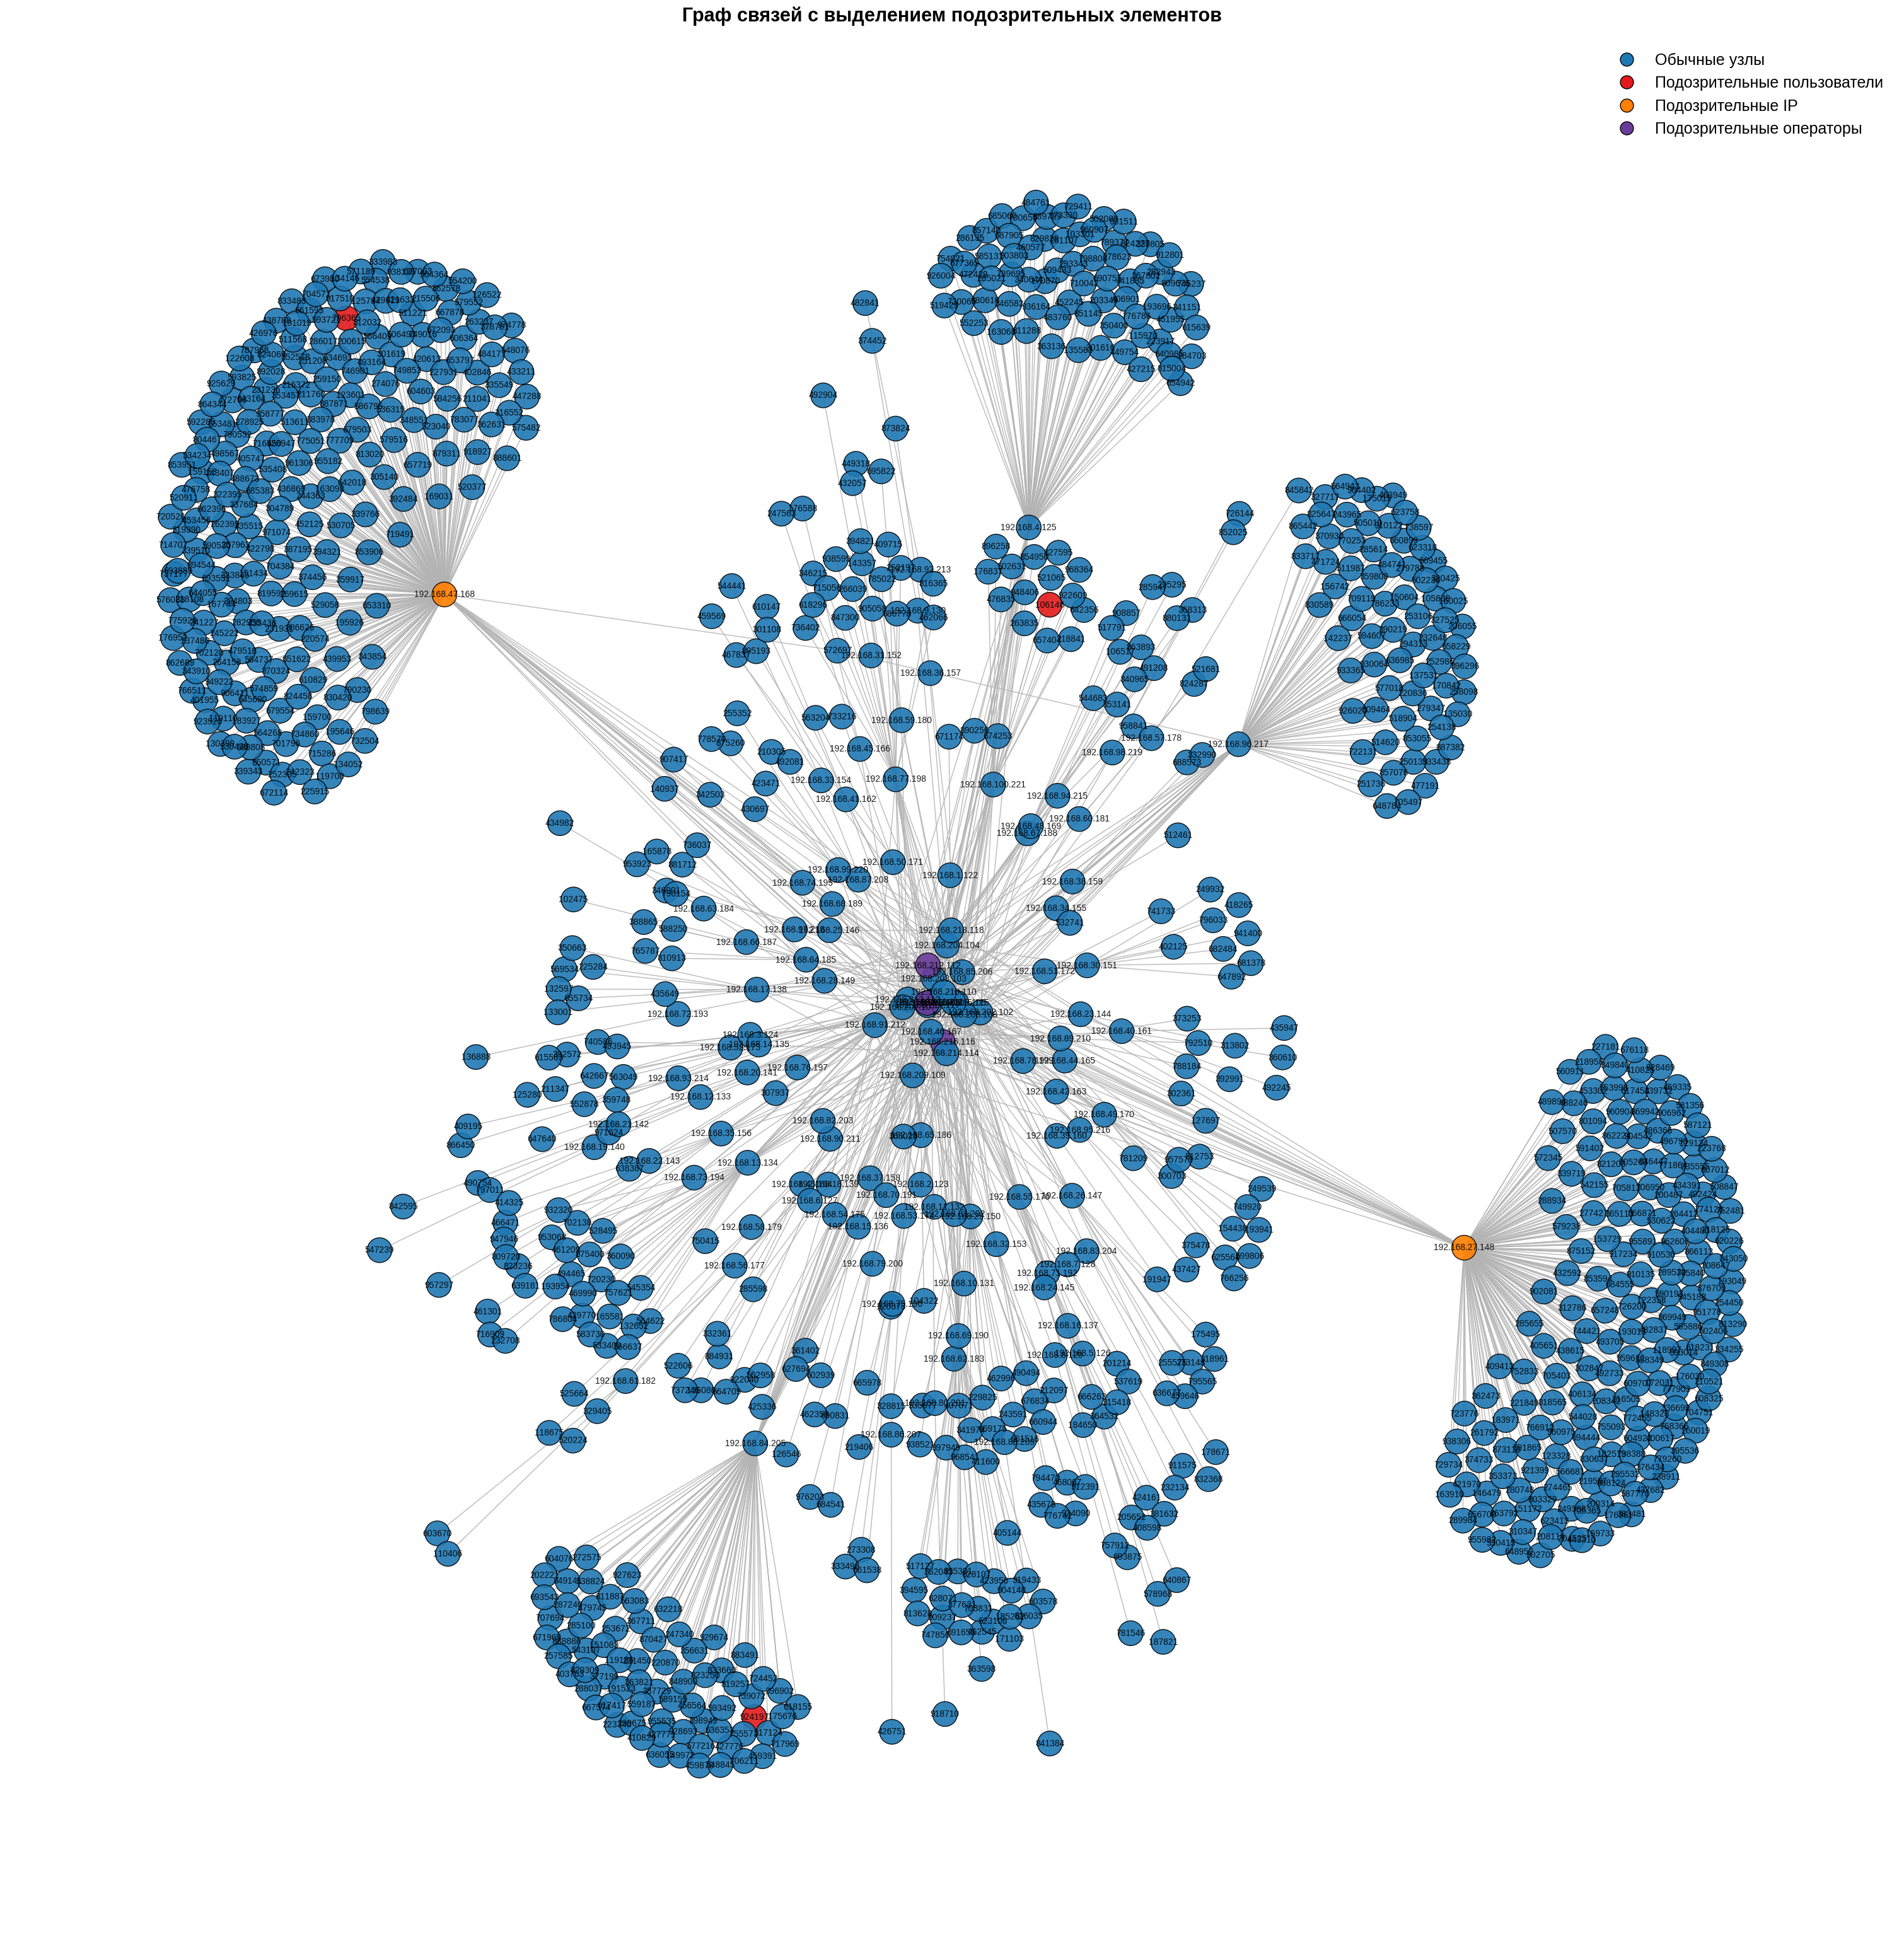

In [ ]:
# Увеличиваем размер фигуры
plt.figure(figsize=(30, 30))

# Создаем граф
G = nx.Graph()

# Определяем подозрительные элементы
suspect_users = [796365, 106146, 924197]
suspect_ips = ['192.168.47.168', '192.168.27.148']
suspect_operators = ['192.168.212.112', '192.168.206.106', '192.168.216.116']

# Добавляем все узлы и ребра
for _, row in df_transactions.iterrows():
    G.add_edge(row['user_id'], row['ip'], label='uses')
    G.add_edge(row['ip'], row['operator_ip'], label='processed_by')

# Получаем позиции всех узлов
pos = nx.spring_layout(G)

# Настройки цветов
NODE_COLORS = {
    'normal': '#1f78b4',      # Темно-синий
    'suspect_user': '#e31a1c', # Ярко-красный
    'suspect_ip': '#ff7f00',   # Ярко-оранжевый
    'suspect_operator': '#6a3d9a' # Темно-фиолетовый
}

EDGE_COLORS = {
    'normal': '#b3b3b3',      # Светло-серый
    'suspect': '#e31a1c'      # Ярко-красный
}

# Определяем цвета для узлов
node_colors = []
for node in G.nodes():
    if node in suspect_users:
        node_colors.append(NODE_COLORS['suspect_user'])
    elif node in suspect_ips:
        node_colors.append(NODE_COLORS['suspect_ip'])
    elif node in suspect_operators:
        node_colors.append(NODE_COLORS['suspect_operator'])
    else:
        node_colors.append(NODE_COLORS['normal'])

# Определяем цвета для ребер
edge_colors = []
for u, v in G.edges():
    if (u in suspect_users and v in suspect_ips) or (u in suspect_ips and v in suspect_operators):
        edge_colors.append(EDGE_COLORS['suspect'])
    else:
        edge_colors.append(EDGE_COLORS['normal'])

# Рисуем граф с темными подписями
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,
    edge_color=edge_colors,
    node_size=800,
    font_size=10,
    font_color='black',  # Черный цвет для подписей узлов
    alpha=0.9,
    edgecolors='black',  # Черная обводка узлов
    linewidths=1
)

# Создаем легенду
legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', label='Обычные узлы',
               markerfacecolor=NODE_COLORS['normal'], markersize=15, markeredgecolor='black'),
    plt.Line2D([0], [0], marker='o', color='w', label='Подозрительные пользователи',
               markerfacecolor=NODE_COLORS['suspect_user'], markersize=15, markeredgecolor='black'),
    plt.Line2D([0], [0], marker='o', color='w', label='Подозрительные IP',
               markerfacecolor=NODE_COLORS['suspect_ip'], markersize=15, markeredgecolor='black'),
    plt.Line2D([0], [0], marker='o', color='w', label='Подозрительные операторы',
               markerfacecolor=NODE_COLORS['suspect_operator'], markersize=15, markeredgecolor='black')
]

# Настраиваем легенду
legend = plt.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=18,  # Увеличиваем размер шрифта
    framealpha=1,  # Убираем прозрачность фона
    labelcolor='black',  # Черный цвет текста
    edgecolor='black',  # Черная граница
    facecolor='white'  # Белый фон
)

# Настраиваем заголовок
plt.title(
    "Граф связей с выделением подозрительных элементов",
    fontsize=22,  # Увеличиваем размер
    fontweight='bold',  # Жирный шрифт
    pad=20,  # Отступ от графика
    color='black'
)

# Улучшаем общее отображение
plt.grid(False)
plt.axis('off')

plt.show()

Видно, как выделяются крупные узлы для 192.168.47.168 и 192.168.27.148.



---



***Применение метода машинного обучения для выявления аномалий среди пользователей и операторов***

ML-модель для детекции аномалий, которая будет анализировать поведенческие профили пользователей и операторов. Используем изолирующий лес (Isolation Forest)

1. Подготовка данных и Feature Engineering
Сначала создадим признаки для пользователей и операторов

In [ ]:
# Признаки для пользователей
user_features = df_transactions.groupby('user_id').agg({
    'order_price': ['mean', 'max', 'sum'],
    'order_id': 'count',  # количество заказов
    'device': lambda x: x.nunique()  # разнообразие устройств
}).reset_index()
user_features.columns = ['user_id', 'avg_price', 'max_price', 'total_spent', \
                         'num_orders', 'unique_devices']


# Признаки для операторов
operator_features = df_transactions.groupby('operator_ip').agg({
    'order_price': ['mean', 'max', 'sum'],
    'order_id': 'count',
    'user_id': 'nunique',  # количество уникальных пользователей
    'device': 'nunique'
}).reset_index()
operator_features.columns = ['operator_ip', 'avg_price', 'max_price', \
                             'total_processed', 'num_orders', 'unique_users', \
                             'unique_devices']

# Нормализация данных
scaler = StandardScaler()
user_features_scaled = scaler.fit_transform(user_features.drop('user_id', axis=1))
operator_features_scaled = scaler.fit_transform(operator_features.\
                                                drop('operator_ip', axis=1))

2. Детекция аномалий через Isolation Forest

In [ ]:
# Для пользователей
user_iforest = IsolationForest(contamination=0.01, random_state=42)
user_features['anomaly_score'] = user_iforest.fit_predict(user_features_scaled)

# Для операторов
operator_iforest = IsolationForest(contamination=0.3, random_state=42)
operator_features['anomaly_score'] = operator_iforest.\
fit_predict(operator_features_scaled)

In [ ]:
# Вывод подозрительных пользователей
suspect_users = user_features[user_features['anomaly_score'] == -1].\
sort_values('total_spent', ascending=False)
print("Подозрительные пользователи:")
suspect_users

Подозрительные пользователи:


,user_id,avg_price,max_price,total_spent,num_orders,unique_devices,anomaly_score
857,924197,1284.0,1878,6420,5,3,-1
315,397949,1018.6,1829,5093,5,3,-1
37,142237,1014.2,1598,5071,5,2,-1
246,340644,902.6,1629,4513,5,2,-1
664,720230,974.5,1798,3898,4,1,-1
232,332361,1868.5,2438,3737,2,2,-1
792,853594,671.6,1299,3358,5,2,-1
735,796365,637.8,1090,3189,5,3,-1
4,106146,631.6,1070,3158,5,3,-1
275,363028,728.0,1124,2184,3,3,-1


In [ ]:
# Вывод подозрительных операторов
suspect_operators = operator_features[operator_features['anomaly_score'] == -1].\
sort_values('total_processed', ascending=False)
print("\nПодозрительные операторы:")
suspect_operators


Подозрительные операторы:


,operator_ip,avg_price,max_price,total_processed,num_orders,unique_users,unique_devices,anomaly_score
10,192.168.212.112,911.142857,2438,57402,63,60,3,-1
9,192.168.211.111,736.881356,1635,43476,59,59,3,-1
11,192.168.213.113,729.000000,1878,36450,50,50,3,-1
16,192.168.218.118,907.027027,1878,33560,37,37,3,-1
8,192.168.210.110,699.533333,1529,31479,45,45,3,-1
7,192.168.209.109,750.763158,1844,28529,38,38,3,-1


Как видим, выделенные ранее подозрительные пользователи (924197, 796365, 106146) вошли в число аномалий, выявленных ML-моделью.

Один из выделенных ранее подозрительных операторов (192.168.212.112) вошел в число аномалий, выявленных ML-моделью.



---



**ВЫВОД**

По совокупности факторов в качестве наиболее подозрительных были выделены пользователи с идентификаторами пользователей 796365 (наиболее подозрительный), 106146 и 924197.

Отметим также, что они совершали заказы с разных устройств (mobile, unknown, web), что может указывать на использование ботов или подмену устройств.

<br>

Самые подозрительные ip адреса пользователей - 192.168.47.168 (наиболее подозрительный), 192.168.27.148.

Отметим, что эти ip адреса пользователей ассоциированы с использованием "unknown" устройства, что типично для автоматизированных скриптов.

<br>

По совокупности факторов в качестве наиболее подозрительных были выделены операторы с ip 192.168.212.112 (наиболее подозрительный), 192.168.206.106, 192.168.216.116.

При этом по операторам с ip 192.168.216.116 и 192.168.206.106 было относительно много заказов с "пустыми" позициями (потенциально тестовые или фейковые заказы).

<br>

При этом между подозрительными пользователями и подозрительными операторами прослеживаются взаимосвязи - т.е. они могут находиться в сговоре.

Так, например, была отслежена связь ip адреса пользователя 192.168.47.168 с ip оператора 192.168.212.112 для пользователя с id 796365.

Треугольник пользователь (796365) → IP (192.168.47.168) → оператор (192.168.212.112) — может быть индикатором мошеннической схемы. Возможно, это внутренний сотрудник или взломанная учетная запись оператора.




---



# **ЗАДАНИЕ 3**

**Распредели компенсацию в размере 90 000 рублей среди пострадавших клиентов и аргументируй свое решение**

Обоснование системы расчета компенсаций

## Бизнес-задача
Распределим **90 000 рублей** компенсации среди клиентов, пострадавших от сбоя в системе заказов, учитывая:
- Реальный ущерб
- Лояльность клиентов
- Общий объем заказов

<br>

## Формула расчета
Для каждого клиента компенсация рассчитывается по формуле:


Компенсация_i = [ (Ущерб_i / max(Ущерб) × 0.7) +
                (Лояльность_i / max(Лояльность) × 0.2) +
                (ОбщийОбъем_i / max(ОбщийОбъем) × 0.1) ] ×
                (90000 / ∑scores)

Где:
- Ущерб_i = сумма потерянных заказов клиента
- Лояльность_i = количество заказов клиента  
- ОбщийОбъем_i = общая сумма заказов клиента



In [ ]:
Math(r"Компенсация_i = \left(\frac{Ущерб_i}{max(Ущерб)} \times 0.7 + \frac{Лояльность_i}{max(Лояльность)} \times 0.2 + \frac{ОбщийОбъем_i}{max(ОбщийОбъем)} \times 0.1\right) \times \frac{90000}{\sum scores}")

<IPython.core.display.Math object>



---



## Ключевые этапы обработки данных

<br>

- Фильтрация данных:

Выбираем только заказы с проблемами (те, для которых данные по полю order, т.е. по наименованиям заказанных пицц, были утеряны)

Учитываем только клиентов с подтвержденным ущербом (damage > 0)

- Нормализация показателей:

Приводим все метрики к диапазону [0,1] делением на максимальное значение

- Расчет компенсации:

Вычисляем интегральный score для каждого клиента

Распределяем общий фонд 90 000 руб пропорционально score


<br>

## Визуализация результатов

Итоговая таблица содержит:

| ID  | Ущерб  | Число заказов | Общая сумма | Компенсация |
|-----|--------|---------------|-------------|-------------|
| 142 | ₽4200  | 15            | ₽8400       | ₽5200.50    |
| 106 | ₽3800  | 12            | ₽5760       | ₽4650.75    |

<br>

С визуализацией:

🟠 Оранжевые гистограммы - относительный размер ущерба

🟢 Зеленые гистограммы - относительный размер компенсации


<br>


## Ключевые преимущества метода

- Справедливость:

Основной вес (70%) у реального ущерба.

Учет лояльности (20%) и общего объема (10%) как дополнительных факторов

(т.е. Поощрение лояльности (частота заказов) и учет масштаба (общий объем)).

Баланс интересов — не позволяет крупным клиентам доминировать только за счет объема.

- Прозрачность:

Четкая формула расчета

Нормализация показателей


- Гибкость:

Веса факторов можно легко корректировать

Метод масштабируется на любой размер выборки



---



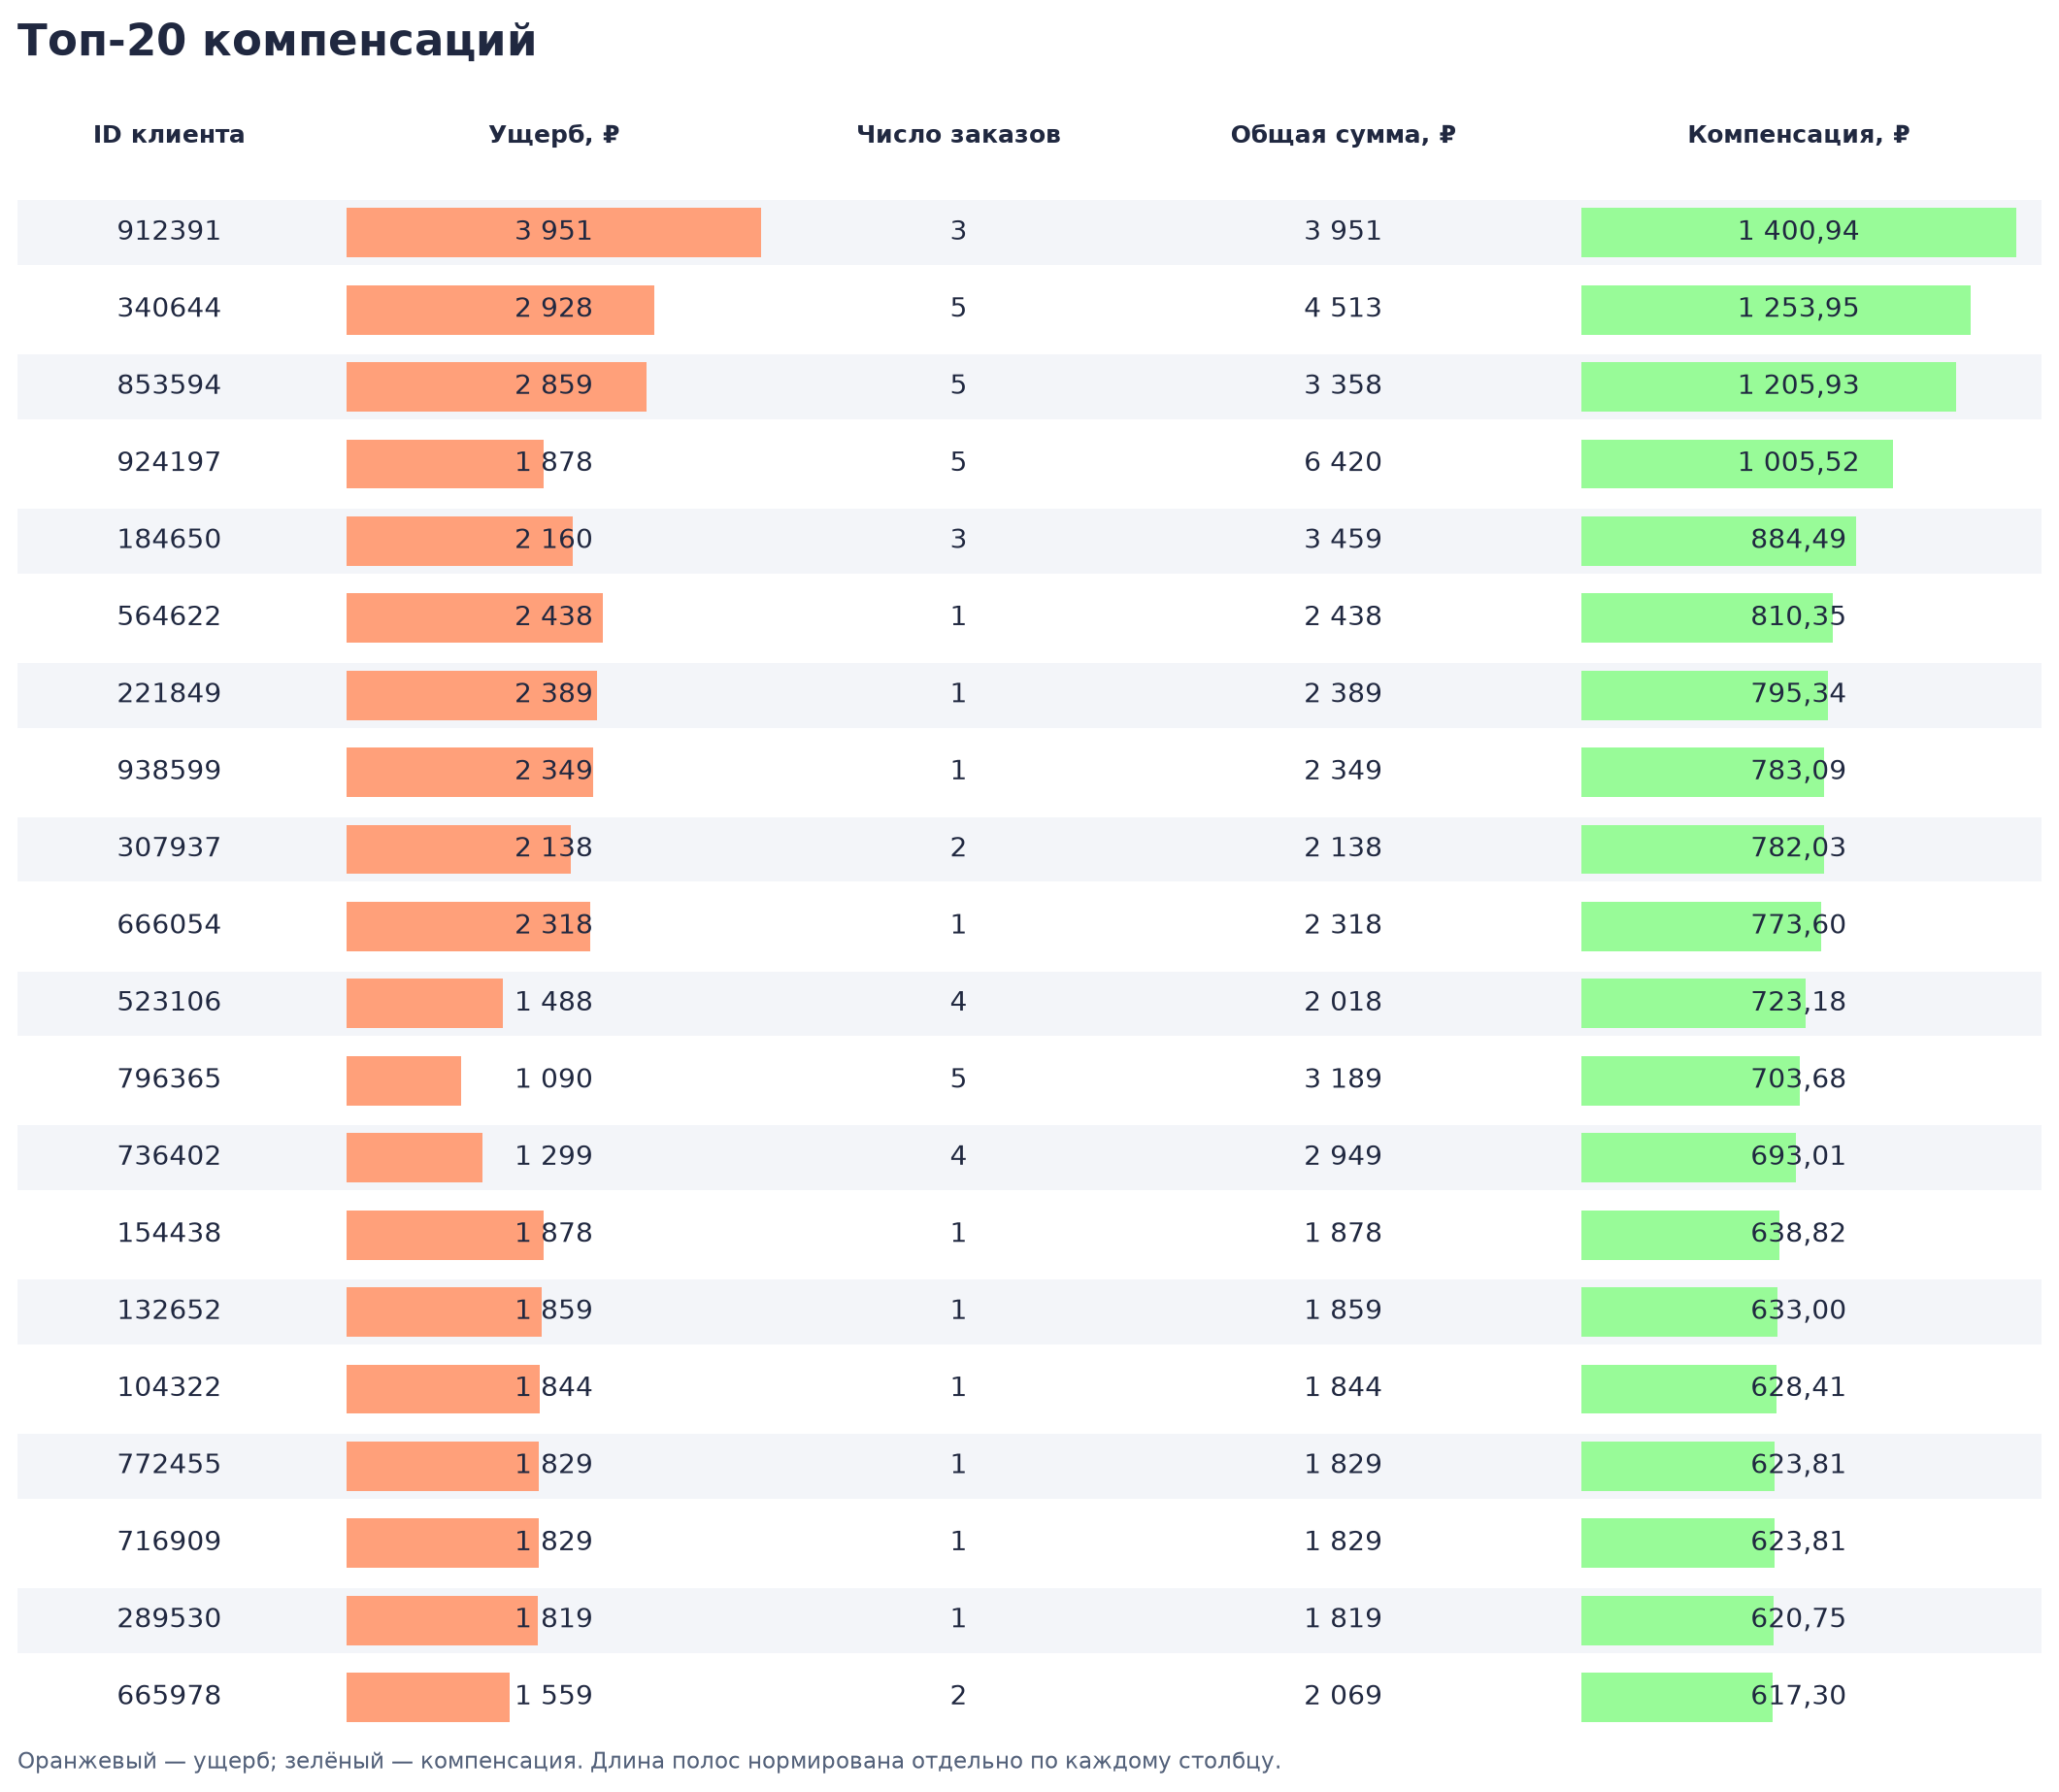

In [ ]:
# Константы
TOTAL_COMPENSATION = 90000
K1 = 0.7  # Основной вес ущерба
K2 = 0.2  # Вес лояльности
K3 = 0.1  # Вес общего объема

# Фильтруем только пользователей с ущербом
df_compensation = df_transactions.copy()
df_compensation['order'] = df_compensation['order'].fillna('MISSING')
df_compensation['is_missing'] = df_compensation['order'] == 'MISSING'

# Группируем и оставляем только тех, у кого damage > 0
user_stats = df_compensation.groupby('user_id').agg(
    total_volume=('order_price', 'sum'),
    order_count=('order_id', 'count'),
    damage=('order_price', lambda x: x[df_compensation['is_missing']].sum())
).reset_index()

user_stats = user_stats[user_stats['damage'] > 0]

# Нормализация
for col in ['damage', 'order_count', 'total_volume']:
    user_stats[f'{col}_norm'] = user_stats[col] / user_stats[col].max()

# Расчет компенсации
user_stats['compensation_score'] = (
    user_stats['damage_norm'] * K1 +
    user_stats['order_count_norm'] * K2 +
    user_stats['total_volume_norm'] * K3
)

# Распределение бюджета
user_stats['compensation'] = (user_stats['compensation_score'] / \
                              user_stats['compensation_score'].sum()) * TOTAL_COMPENSATION
user_stats['compensation'] = user_stats['compensation'].round(2)

# Итоговый отчет
final_result = user_stats[['user_id', 'damage', 'order_count', 'total_volume', 'compensation']]
final_result.columns = ['ID', 'Ущерб', 'Число заказов', 'Общая сумма', 'Компенсация']
final_result = final_result.sort_values('Компенсация', ascending=False)

final_result.to_csv(OUTPUT_DIR / 'users_compensation.csv',
                    index=False,
                    encoding='utf-8-sig')

# Таблица с полосами как изображение: оформление сохраняется при просмотре на GitHub.
def plot_compensation_table(data):
    from matplotlib.patches import Rectangle

    table = data.head(20).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 10.5), facecolor='white')
    ax.set_facecolor('white')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, len(table) + 2.8)
    ax.axis('off')
    boundaries = [0, 0.15, 0.38, 0.55, 0.76, 1]
    headers = ['ID клиента', 'Ущерб, ₽', 'Число заказов', 'Общая сумма, ₽', 'Компенсация, ₽']
    ax.text(0, len(table) + 2.3, 'Топ-20 компенсаций',
            fontsize=18, weight='bold', color='#202840')
    for left, right, header in zip(boundaries, boundaries[1:], headers):
        ax.text((left + right) / 2, len(table) + 1.25, header,
                ha='center', va='center', fontsize=10, weight='bold', color='#202840')
    max_damage = table['Ущерб'].max()
    max_compensation = table['Компенсация'].max()
    for i, row in table.iterrows():
        y = len(table) - i
        if i % 2 == 0:
            ax.add_patch(Rectangle((0, y - 0.42), 1, 0.84,
                                   facecolor='#F3F5F9', edgecolor='none'))
        for col, value, maximum, color in [
            (1, row['Ущерб'], max_damage, '#FFA07A'),
            (4, row['Компенсация'], max_compensation, '#98FB98'),
        ]:
            left, right = boundaries[col:col + 2]
            width = (right - left - 0.025) * value / maximum
            ax.add_patch(Rectangle((left + 0.0125, y - 0.32), width, 0.64,
                                   facecolor=color, edgecolor='none'))
        values = [str(int(row['ID'])), f"{row['Ущерб']:,.0f}".replace(',', ' '),
                  str(int(row['Число заказов'])),
                  f"{row['Общая сумма']:,.0f}".replace(',', ' '),
                  f"{row['Компенсация']:,.2f}".replace(',', ' ').replace('.', ',')]
        for left, right, value in zip(boundaries, boundaries[1:], values):
            ax.text((left + right) / 2, y, value, ha='center', va='center',
                    fontsize=11, color='#202840')
    ax.text(0, 0.08, 'Оранжевый — ущерб; зелёный — компенсация. Длина полос нормирована отдельно по каждому столбцу.',
            fontsize=9, color='#526079')
    fig.tight_layout(pad=1.5)
    return fig

fig = plot_compensation_table(final_result)
fig.savefig(OUTPUT_DIR / 'compensation-top20.png', dpi=180, bbox_inches='tight', facecolor='white')
plt.show()


Вывод общих итогов

In [ ]:
print(f"Количество пользователей, которым будет выплачена компенсация: \
{final_result['ID'].count()}")
print(f"Общая сумма ущерба пользователям: {final_result['Ущерб'].sum()}")
print(f"Общая сумма выплачиваемой пользователям компенсации: \
{round(final_result['Компенсация'].sum(), 2)}")
print(f"Процент покрытия ущерба выплачиваемой пользователям компенсацией: \
{round(final_result['Компенсация'].sum()/final_result['Ущерб'].sum()*100, 2)}%")

Количество пользователей, которым будет выплачена компенсация: 258
Общая сумма ущерба пользователям: 225598
Общая сумма выплачиваемой пользователям компенсации: 90000.04
Процент покрытия ущерба выплачиваемой пользователям компенсацией: 39.89%




---





---

